# B16 — Pandas vs PySpark: Correctness, Performance, and Scalability

**Project:** Decomposing Racial Gaps in Mortgage Denial Rates: A Large-Scale Analysis of the 2024 U.S. HMDA Market

This notebook covers two project deliverables:

1. **Section 7 — Correctness comparison:** compare Pandas (B06) and PySpark (B07) independent analytical inputs, population definition, grouping variables, and aggregation logic.
2. **Section 8 — Performance and scalability experiment:** benchmark an identical grouped-aggregation workload at 25%, 50%, and 100% of the analytical dataset.

The notebook independently validates `B06_analytic.parquet` (Pandas) and `B07_analytic.parquet` (PySpark), then compares the two analytical implementations. It does not repeat B06/B07 cleaning or the full EDA workflows.

### Important design decisions

- The approved proposal defines the benchmark as grouping by `derived_race` and `loan_type`, then calculating application counts, denied-application counts, and denial rates.
- The S0 analytical population is used independently in B06 and B07. The denial-rate denominator follows `action_taken IN (1, 2, 3)`.
- Existing `derived_race` values are preserved; no new race mapping is created.
- Pandas reads Parquet data in Arrow batches to control memory use.
- PySpark runs in local mode on the same machine.
- Section 8 uses B06 as the single canonical benchmark source. One shared set of nested Parquet samples is created once and read by both Pandas and PySpark.
- Spark initialization and sample preparation are excluded from measured workload time. PyArrow writes the local benchmark samples so Windows Hadoop utilities are not required for sample creation.
- Only small aggregated Spark results are collected to the driver. The full analytical dataset is never converted to Pandas.

### Before running

1. Place both Parquet inputs directly in `B16 - Pandas Spark Compare/input/`.
2. If task-folder discovery fails, set `B16_TASK_DIR` to the task directory.
3. Run the notebook from top to bottom.
4. Review the generated validation outputs before using the benchmark results in the technical report.

**Note:** The notebook is designed to run against the project's actual Parquet file. Since that data file is not attached to this notebook-generation session, the code has been syntax-checked but has not been executed against the full dataset.

**Stage 6 revision:** Benchmark execution now uses equivalent measured work in both engines, validates denial flags within the aggregation action, records complete run metadata, and reports an explicitly named PySpark-over-Pandas speedup ratio.


**Stage 6 revision:**
- **[CHANGE]** Split long configuration, population-validation, correctness, and final-check cells into smaller documented steps.
- **[ADD]** Added docstrings to reusable functions, a common output-metadata reporter, and a more complete final artifact inventory.
- **[REMOVE]** Removed a duplicate Step 5.2 Markdown block and an obsolete notebook-filename fallback from task-folder discovery.
- **[CHANGE]** Preserved the existing S0 definition, grouping specifications, correctness tolerances, sample proportions, and benchmark repetition settings. No analytical rule or benchmark setting is intentionally changed in this stage.


**Windows local-write fix:** Step 4.4 now writes Parquet samples with PyArrow rather than Spark's Hadoop-backed local writer. This avoids the `winutils.exe` dependency for sample creation. The Spark read/aggregation steps remain unchanged. The previously suggested `RawLocalFileSystem` workaround is not required and should not be added.


**[CHANGE] Windows compatibility:** Section 8 runs a CSV-based benchmark converted from existing Arrow-validated B06 Parquet samples, while Section 7 remains an independent B06-vs-B07 Parquet correctness analysis. CSV conversion is excluded from runtime, and all benchmarks are correctness-gated.


## 0. Environment, paths, and configuration

**Input:** The `B16 - Pandas Spark Compare/` task directory, containing `input/B06_analytic.parquet` (Pandas) and `input/B07_analytic.parquet` (PySpark); optional `B16_TASK_DIR` override.

**Process:** Configure experiment settings, locate the B16 task folder and set standard input/output/document paths. No external B06/B07 folder fallback is used.

**Output:** `TASK_DIR`, `INPUT_DIR`, `OUTPUT_DIR`, `DOCUMENTS_DIR`, and `BENCHMARK_DATA_DIR`.


In [5]:
# [CHANGE] Step 0.1 — Centralize imports, settings, and task directories
import os
import sys
import time
import platform
import warnings
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import pyarrow.csv as pacsv
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark import StorageLevel

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
REPETITIONS = 5
PANDAS_BATCH_SIZE = 200_000
DENIAL_RATE_TOLERANCE = 1e-10
MISSING_GROUP = "__MISSING__"
REBUILD_BENCHMARK_CSV = False  # [ADD] Set True only to overwrite an existing CSV copy.
REBUILD_BENCHMARK_SAMPLES = True  # [CHANGE] Reuse existing samples; set True explicitly to rebuild.
SPARK_APP_NAME = "B16_Pandas_vs_PySpark_Comparison"
SHUFFLE_PARTITIONS = max(8, min(200, (os.cpu_count() or 2) * 2))

# Optional B16 task directory override; input files are fixed within input/.
MANUAL_TASK_DIR = os.environ.get("B16_TASK_DIR", "").strip()
TASK_FOLDER_NAME = "B16 - Pandas Spark Compare"

### 0.2 Resolve the two analytical inputs

**Input:** `B16 - Pandas Spark Compare/input/B06_analytic.parquet` and `B07_analytic.parquet`.

**Process:** Identify the B16 task folder from the current working directory (or `B16_TASK_DIR`), create its standard folders, and validate both files in `input/`. `Path.resolve()` normalizes paths; `.is_file()` checks that each file exists. Missing inputs raise a clear error rather than triggering a search elsewhere.

**Output:** `B06_PATH` for Pandas, `B07_PATH` for PySpark, and `OUTPUT_DIR` for generated files. Stage 2 uses B06 for Pandas and B07 for PySpark; aggregation methods are unchanged.

### 0.2A Define task-folder and input-path resolvers

**Input:** The optional `B16_TASK_DIR` override and the configured task-folder name.  
**Process:** Define reusable path-resolution functions. The resolver checks the explicit override first, then searches the current directory and its parents for the B16 task folder. Input files are accepted only from the task folder's `input/` directory.  
**Output:** `locate_task_dir()` and `resolve_analytic_parquet()` helper functions.


In [6]:
# Step 0.2A — Define task-folder and input-path resolvers

from pathlib import Path

def locate_task_dir() -> Path:
    """Locate the B16 task directory."""

    # Option 1: Manually specified directory
    if MANUAL_TASK_DIR:
        task_dir = Path(MANUAL_TASK_DIR).expanduser().resolve()

        if not task_dir.is_dir():
            raise FileNotFoundError(
                f"B16 task directory not found: {task_dir}"
            )

        return task_dir

    # Option 2: Search current folder and parent folders
    current = Path.cwd().resolve()

    for base in (current, *current.parents):

        if base.name == TASK_FOLDER_NAME:
            return base

        candidate = base / TASK_FOLDER_NAME

        if candidate.is_dir():
            return candidate.resolve()

    raise FileNotFoundError(
        f"Cannot locate '{TASK_FOLDER_NAME}'. "
        "Open the project folder or set B16_TASK_DIR."
    )


def resolve_analytic_parquet(task_code: str) -> Path:
    """Locate an upstream task's analytical Parquet output."""

    # Step 1: Identify the shared project directory
    project_dir = TASK_DIR.parent

    # Step 2: Find the upstream task folder
    task_dirs = sorted(
        path for path in project_dir.iterdir()
        if path.is_dir() and path.name.startswith(f"{task_code} - ")
    )

    # Step 3: Find the expected analytical output
    matches = [
        folder / "output" / f"{task_code}_analytic.parquet"
        for folder in task_dirs
        if (folder / "output" / f"{task_code}_analytic.parquet").is_file()
    ]

    # Step 4: Validate the resolved path
    if len(matches) != 1:
        raise FileNotFoundError(
            f"{task_code}: expected one analytical Parquet output, "
            f"found {len(matches)}. Matches: {matches}"
        )

    return matches[0].resolve()



### 0.2B Initialize the task directories and resolve inputs

**Input:** The B16 folder resolver and the expected B06/B07 input filenames.  
**Process:** Create the standard `input/`, `output/`, `documents/`, and benchmark-output directories. Resolve both Parquet files without searching external folders.  
**Output:** Canonical B16 directory paths, `B06_PATH`, and `B07_PATH`.


In [7]:
# [CHANGE] Step 0.2B — Initialize task folders and resolve B06/B07

# Step 1: Initialize task directories
TASK_DIR = locate_task_dir()

INPUT_DIR = TASK_DIR / "input"
OUTPUT_DIR = TASK_DIR / "output"
DOCUMENTS_DIR = TASK_DIR / "documents"
BENCHMARK_DATA_DIR = OUTPUT_DIR / "benchmark_data"

for directory in (
    INPUT_DIR,
    OUTPUT_DIR,
    DOCUMENTS_DIR,
    BENCHMARK_DATA_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)

# Step 2: Resolve upstream analytical outputs
B06_PATH = resolve_analytic_parquet("B06")
B07_PATH = resolve_analytic_parquet("B07")

# Step 3: Report resolved configuration
print("B16 task:", TASK_DIR)
print("Pandas input (B06):", B06_PATH)
print("PySpark input (B07):", B07_PATH)
print("Output folder:", OUTPUT_DIR)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__, "| PyArrow:", pa.__version__)

B16 task: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare
Pandas input (B06): D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B06 - Clean\output\B06_analytic.parquet
PySpark input (B07): D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B07 - Spark Clean\output\B07_analytic.parquet
Output folder: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output
Python: 3.13.6
Pandas: 2.2.3 | PyArrow: 25.0.1


### 0.2C Define a reusable output-metadata reporter

**Input:** A generated file path and optional row/column counts.  
**Process:** Read the file size after it has been written and print its resolved path and available dimensions.  
**Output:** A consistent metadata line for generated artifacts.


In [8]:
# [ADD] Step 0.2C — Report generated artifact metadata
def report_output_metadata(path, row_count=None, column_count=None):
    """Print a generated artifact's path, byte size, and optional table dimensions."""
    path = Path(path)
    details = [f"Saved: {path.resolve()}", f"size_bytes={path.stat().st_size}"]
    if row_count is not None:
        details.append(f"rows={row_count}")
    if column_count is not None:
        details.append(f"columns={column_count}")
    print(" | ".join(details))


### 0.3 Initialize Spark

**Input:** `SPARK_APP_NAME` and `SHUFFLE_PARTITIONS` from the initial configuration.

**Process:** Start the local Spark session and time initialization separately from benchmark runs.

**Output:** `spark` and `SPARK_STARTUP_SECONDS`.

In [9]:
# Step 0.3 — Initialize Spark and record the startup time

spark_start = time.perf_counter()

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName(SPARK_APP_NAME)
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.shuffle.partitions", str(SHUFFLE_PARTITIONS))
    .getOrCreate()
)

SPARK_STARTUP_SECONDS = time.perf_counter() - spark_start
spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Spark startup time (seconds):", round(SPARK_STARTUP_SECONDS, 3))
print("Spark master:", spark.sparkContext.master)
print("Shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))


Spark version: 4.3.0
Spark startup time (seconds): 13.528
Spark master: local[*]
Shuffle partitions: 40


### 0.4 Record the execution environment

**Input:** Runtime software/hardware information and the resolved analytical paths.

**Process:** Collect a compact environment record; use `psutil` only if available.

**Output:** `B16_compare_environment.csv` in `output/` and a displayed environment table.

In [10]:
# Step 0.4 — Save the computational environment

try:
    import psutil
    memory_total_gb = psutil.virtual_memory().total / (1024 ** 3)
    memory_available_gb = psutil.virtual_memory().available / (1024 ** 3)
except Exception:
    memory_total_gb = np.nan
    memory_available_gb = np.nan

environment = pd.DataFrame([{
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "pyarrow_version": pa.__version__,
    "numpy_version": np.__version__,
    "spark_version": spark.version,
    "spark_master": spark.sparkContext.master,
    "cpu_cores": os.cpu_count(),
    "system_memory_gb": memory_total_gb,
    "available_memory_gb_at_start_gb": memory_available_gb,
    "spark_startup_seconds": SPARK_STARTUP_SECONDS,
    "shuffle_partitions": SHUFFLE_PARTITIONS,
    "spark_adaptive_enabled": spark.conf.get("spark.sql.adaptive.enabled"),
    "input_path": str(B06_PATH.resolve()),  # [CHANGE] Legacy field retained for compatibility.
    "pandas_input_path": str(B06_PATH),
    "pyspark_input_path": str(B07_PATH),
}])

environment_path = OUTPUT_DIR / "B16_compare_environment.csv"
environment.to_csv(environment_path, index=False)
report_output_metadata(environment_path, len(environment), len(environment.columns))
display(environment)


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_environment.csv | size_bytes=674 | rows=1 | columns=15


,python_version,pandas_version,pyarrow_version,numpy_version,spark_version,spark_master,cpu_cores,system_memory_gb,available_memory_gb_at_start_gb,spark_startup_seconds,shuffle_partitions,spark_adaptive_enabled,input_path,pandas_input_path,pyspark_input_path
0,3.13.6,2.2.3,25.0.1,2.2.3,4.3.0,local[*],20,27.792355,6.596855,13.528165,40,true,D:\whoever holds this long stick\neu_ba65_bigd...,D:\whoever holds this long stick\neu_ba65_bigd...,D:\whoever holds this long stick\neu_ba65_bigd...


## 1. Independent input inspection and analytical population

**Input:** `input/B06_analytic.parquet` (Pandas via PyArrow) and `input/B07_analytic.parquet` (PySpark).

**Process:** Inspect each input schema independently, then profile all records and the explicitly defined analytical population S0 (`action_taken` in `{1, 2, 3}`). Validate `is_denied` against `action_taken == 3` for S0. Record rows outside S0 without treating them as cleaning removals. Compare input columns, S0 sizes, outcomes, and basic group distributions without changing either input.

**Output:** `B16_compare_schema_check.csv`, `B16_compare_input_profile.csv`, `B16_compare_population_checks.csv`, and `B16_compare_group_checks.csv`. Discrepancies are reported, not silently reconciled. Counts must be read from executable output, not assumed to agree.

### 1.1 Inspect B06 and B07 schemas

**Input:** Both analytical Parquet files. **Process:** Read only Parquet metadata using PyArrow for B06 and Spark for B07, compare column presence and display missing columns. **Output:** `B16_compare_schema_check.csv`.

In [11]:
# [CHANGE] Step 1.1 — Inspect independent B06/B07 schemas
pandas_dataset = ds.dataset(str(B06_PATH), format="parquet")
source_df = spark.read.parquet(str(B07_PATH))
required_benchmark_columns = ["derived_race", "loan_type", "action_taken", "is_denied"]
pandas_schema = {field.name: str(field.type) for field in pandas_dataset.schema}
spark_schema = dict(source_df.dtypes)
missing_by_engine = {
    "pandas_B06": sorted(set(required_benchmark_columns) - set(pandas_schema)),
    "pyspark_B07": sorted(set(required_benchmark_columns) - set(spark_schema)),
}
if any(missing_by_engine.values()):
    raise ValueError(f"Required input columns missing: {missing_by_engine}")
schema_check = pd.DataFrame([
    {"column": col, "pandas_type": pandas_schema.get(col),
     "pyspark_type": spark_schema.get(col),
     "in_both": col in pandas_schema and col in spark_schema,
     "type_string_equal": pandas_schema.get(col) == spark_schema.get(col)}
    for col in sorted(set(pandas_schema) | set(spark_schema))
])
schema_path = OUTPUT_DIR / "B16_compare_schema_check.csv"
schema_check.to_csv(schema_path, index=False)
print(f"B06 columns: {len(pandas_schema)} | B07 columns: {len(spark_schema)}")
print("Shared columns:", int(schema_check["in_both"].sum()))
print("Schema report:", schema_path, "| rows:", len(schema_check),
      "| cols:", len(schema_check.columns), "| bytes:", schema_path.stat().st_size)
display(schema_check.loc[~schema_check["in_both"]].head(20))

B06 columns: 169 | B07 columns: 169
Shared columns: 169
Schema report: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_schema_check.csv | rows: 169 | cols: 5 | bytes: 7621


,column,pandas_type,pyspark_type,in_both,type_string_equal


### 1.2 Profile B06 using Pandas and PyArrow

**Input:** B06 analytical Parquet. **Process:** Read only outcome columns in memory-bounded Arrow record batches. `pd.to_numeric(errors="coerce")` validates numeric interpretation; invalid values remain counted. **Output:** B06 full-input and S0 row/outcome metrics.

In [12]:
# [CHANGE] Step 1.2 — Profile Pandas/B06 input in Arrow batches
def pandas_input_profile(dataset, batch_size):
    """Count full-input and S0 outcomes in batches without loading all rows into RAM."""
    metrics = dict(total_rows=0, s0_rows=0, outside_s0_rows=0,
                   denied_rows=0, null_denied_n=0, invalid_denied_n=0,
                   outcome_mismatch_n=0, null_action_n=0)
    for batch in dataset.scanner(columns=["action_taken", "is_denied"],
                                 batch_size=batch_size).to_batches():
        part = batch.to_pandas()
        action = pd.to_numeric(part["action_taken"], errors="coerce")
        denied = pd.to_numeric(part["is_denied"], errors="coerce")
        eligible = action.isin([1, 2, 3])
        selected = denied[eligible]
        metrics["total_rows"] += len(part)
        metrics["s0_rows"] += int(eligible.sum())
        metrics["outside_s0_rows"] += int((~eligible).sum())
        metrics["null_action_n"] += int(action.isna().sum())
        metrics["null_denied_n"] += int(selected.isna().sum())
        metrics["invalid_denied_n"] += int((~selected.isin([0, 1])).sum())
        metrics["outcome_mismatch_n"] += int(
            (selected != action[eligible].eq(3).astype(int)).sum())
        metrics["denied_rows"] += int(selected.eq(1).sum())
    return metrics

pandas_profile = pandas_input_profile(pandas_dataset, PANDAS_BATCH_SIZE)
print("Pandas B06: all rows", f"{pandas_profile['total_rows']:,}",
      "| S0 rows", f"{pandas_profile['s0_rows']:,}")

Pandas B06: all rows 8,136,664 | S0 rows 8,136,664


### 1.3 Profile the PySpark B07 input

**Input:** B07 Spark DataFrame and the S0 rule. **Process:** Aggregate original row counts, eligible/outside-S0 rows, denied records, nulls, and outcome mismatches without changing the source or applying cleaning. **Output:** `spark_profile` for the comparison report.

In [13]:
# [ADD] Step 1.3 — Profile PySpark/B07 independently
_action = F.col("action_taken").cast("int")
_denied = F.col("is_denied").cast("int")
_eligible = _action.isin(1, 2, 3)
_agg = source_df.agg(
    F.count("*").alias("total_rows"),
    F.sum(F.when(_eligible, 1).otherwise(0)).alias("s0_rows"),
    F.sum(F.when(~_eligible | _eligible.isNull(), 1).otherwise(0)).alias("outside_s0_rows"),
    F.sum(F.when(_action.isNull(), 1).otherwise(0)).alias("null_action_n"),
    F.sum(F.when(_eligible & (_denied == 1), 1).otherwise(0)).alias("denied_rows"),
    F.sum(F.when(_eligible & _denied.isNull(), 1).otherwise(0)).alias("null_denied_n"),
    F.sum(F.when(_eligible & (~_denied.isin(0, 1) | _denied.isNull()), 1)
          .otherwise(0)).alias("invalid_denied_n"),
    F.sum(F.when(_eligible & (_denied.isNull() |
        (_denied != F.when(_action == 3, 1).otherwise(0))), 1)
          .otherwise(0)).alias("outcome_mismatch_n"),
).first().asDict()
spark_profile = {k: int(v or 0) for k, v in _agg.items()}
print("PySpark B07: all rows", f"{spark_profile['total_rows']:,}",
      "| S0 rows", f"{spark_profile['s0_rows']:,}")

PySpark B07: all rows 8,136,664 | S0 rows 8,136,664


### 1.4 Compare input populations and outcome definitions

**Input:** Independent B06 and B07 profiles. **Process:** Compare totals and S0 metrics, validate within-source invariants and the denial flag, and report differences. No rows are silently removed or reconciled. **Output:** CSV profiles and comparison checks; an explicit error for invalid outcome definitions.

In [14]:
# [ADD] Step 1.4 — Export a transparent dual-source validation report
profile_rows = []
for engine, path, metrics in [
    ("pandas_B06", B06_PATH, pandas_profile),
    ("pyspark_B07", B07_PATH, spark_profile),
]:
    record = {"engine": engine, "input_path": str(path), **metrics}
    record["denial_rate"] = (metrics["denied_rows"] / metrics["s0_rows"]
                             if metrics["s0_rows"] else np.nan)
    profile_rows.append(record)
input_profile = pd.DataFrame(profile_rows)
metric_names = list(pandas_profile)
population_checks = pd.DataFrame([
    {"metric": key, "pandas_B06": pandas_profile[key],
     "pyspark_B07": spark_profile[key],
     "difference_B06_minus_B07": pandas_profile[key] - spark_profile[key],
     "agree": pandas_profile[key] == spark_profile[key]}
    for key in metric_names
])
for name, frame in [("input_profile", input_profile),
                    ("population_checks", population_checks)]:
    path = OUTPUT_DIR / f"B16_compare_{name}.csv"
    frame.to_csv(path, index=False)
    print(f"Saved: {path} | {len(frame)} rows x {len(frame.columns)} cols | "
          f"{path.stat().st_size} bytes")
display(input_profile)
display(population_checks)
for engine, item in [("B06", pandas_profile), ("B07", spark_profile)]:
    assert item["total_rows"] == item["s0_rows"] + item["outside_s0_rows"], engine
    assert item["s0_rows"] > 0, f"No eligible S0 rows in {engine}"
    assert item["invalid_denied_n"] == 0, f"Invalid S0 denial values in {engine}"
    assert item["outcome_mismatch_n"] == 0, f"S0 denial flags disagree in {engine}"
if not population_checks["agree"].all():
    print("[WARNING] B06 and B07 population profiles differ; review exported checks.")
# [CHANGE] B06 is the canonical sample-size basis for Section 8.
S0_ROW_COUNT = int(pandas_profile["s0_rows"])

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_input_profile.csv | 2 rows x 11 cols | 481 bytes
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_population_checks.csv | 8 rows x 5 cols | 305 bytes


,engine,input_path,total_rows,s0_rows,outside_s0_rows,denied_rows,null_denied_n,invalid_denied_n,outcome_mismatch_n,null_action_n,denial_rate
0,pandas_B06,D:\whoever holds this long stick\neu_ba65_bigd...,8136664,8136664,0,2003276,0,0,0,0,0.246204
1,pyspark_B07,D:\whoever holds this long stick\neu_ba65_bigd...,8136664,8136664,0,2003276,0,0,0,0,0.246204


,metric,pandas_B06,pyspark_B07,difference_B06_minus_B07,agree
0,total_rows,8136664,8136664,0,True
1,s0_rows,8136664,8136664,0,True
2,outside_s0_rows,0,0,0,True
3,denied_rows,2003276,2003276,0,True
4,null_denied_n,0,0,0,True
5,invalid_denied_n,0,0,0,True
6,outcome_mismatch_n,0,0,0,True
7,null_action_n,0,0,0,True


### 1.5 Inspect core-group distributions without changing inputs

**Input:** B06 and B07 `derived_race`, `loan_type`, `action_taken` fields. **Process:** Count S0 rows in each core group in Arrow batches (Pandas) and using Spark groupBy; compare aligned group keys and totals. **Output:** `B16_compare_group_checks.csv`, retaining any unmatched or unequal groups for investigation.

### 1.5A Define the Pandas core-group counter

**Input:** The B06 PyArrow dataset and S0 outcome definition.  
**Process:** Stream only the race, loan-type, and action columns in Arrow batches. Normalize missing group labels and accumulate application counts by race and loan type.  
**Output:** A reusable `pandas_core_groups()` function.


In [15]:
# [CHANGE] Step 1.5A — Define the chunked Pandas group counter
def pandas_core_groups(dataset):
    """Count B06 S0 applications by race and loan type across Arrow batches."""
    totals = {}
    columns = ["derived_race", "loan_type", "action_taken"]

    for batch in dataset.scanner(
        columns=columns, batch_size=PANDAS_BATCH_SIZE
    ).to_batches():
        part = batch.to_pandas()
        valid = pd.to_numeric(
            part["action_taken"], errors="coerce"
        ).isin([1, 2, 3])
        work = part.loc[valid, ["derived_race", "loan_type"]].copy()

        for column in ["derived_race", "loan_type"]:
            work[column] = work[column].astype("string").fillna(MISSING_GROUP)

        for key, count in work.groupby(
            ["derived_race", "loan_type"], dropna=False
        ).size().items():
            normalized_key = tuple(map(str, key))
            totals[normalized_key] = totals.get(normalized_key, 0) + int(count)

    return pd.DataFrame([
        {"derived_race": key[0], "loan_type": key[1], "pandas_rows": count}
        for key, count in totals.items()
    ])


### 1.5B Compare core-group counts from both inputs

**Input:** B06 Arrow batches and the B07 Spark DataFrame.  
**Process:** Calculate S0 counts by the same race-by-loan-type keys, outer-join the results, and retain missing or unequal groups for review.  
**Output:** `B16_compare_group_checks.csv` and the displayed mismatch rows.


In [16]:
# [ADD] Step 1.5B — Compare B06/B07 race-by-loan-type counts
p_groups = pandas_core_groups(pandas_dataset)
s_groups = (
    source_df.filter(F.col("action_taken").cast("int").isin(1, 2, 3))
    .select(
        F.coalesce(F.col("derived_race").cast("string"), F.lit(MISSING_GROUP)).alias("derived_race"),
        F.coalesce(F.col("loan_type").cast("string"), F.lit(MISSING_GROUP)).alias("loan_type"),
    )
    .groupBy("derived_race", "loan_type").count()
    .toPandas().rename(columns={"count": "pyspark_rows"})
)

group_checks = p_groups.merge(
    s_groups, how="outer", on=["derived_race", "loan_type"], indicator=True
)
group_checks[["pandas_rows", "pyspark_rows"]] = (
    group_checks[["pandas_rows", "pyspark_rows"]].fillna(0).astype("int64")
)
group_checks["difference"] = group_checks["pandas_rows"] - group_checks["pyspark_rows"]
group_checks["agree"] = (group_checks["difference"] == 0) & (group_checks["_merge"] == "both")

group_path = OUTPUT_DIR / "B16_compare_group_checks.csv"
group_checks.to_csv(group_path, index=False)
report_output_metadata(group_path, len(group_checks), len(group_checks.columns))
print("Mismatched core groups:", int((~group_checks["agree"]).sum()))
display(group_checks.loc[~group_checks["agree"]].head(20))


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_group_checks.csv | size_bytes=1743 | rows=36 | columns=7
Mismatched core groups: 0


,derived_race,loan_type,pandas_rows,pyspark_rows,_merge,difference,agree


### 1.6 Validate grouping values before correctness calculations

**Input:** The independently loaded B06 (Pandas) and B07 (PySpark) S0 populations, including all shared analytical grouping columns except the high-cardinality lender identifier (`lei`).

**Process:** Compare each observed value and its S0 application count for `derived_race`, `loan_type`, and any shared `dti_bin_coarse`, `state_code`, and `lender_size_bucket` fields. Preserve null groups as `__MISSING__`. Export all mismatches. A final validation gate checks population and the joint `derived_race × loan_type` groups from Step 1.5 and every inspected marginal grouping distribution. This is a strict diagnostic gate: discrepancies stop Section 7 and Section 8 rather than silently adjusting the inputs. `lei` is left to the existing lender-level correctness comparison in Section 7.

**Output:** `B16_compare_group_value_checks.csv` and a printed PASS/FAIL. If the gate fails, examine CSV outputs and resolve upstream differences before running subsequent steps.

### 1.6A Define a memory-bounded categorical value counter

**Input:** The B06 PyArrow dataset, one grouping column, and the S0 outcome definition.  
**Process:** Read the action and selected grouping column in Arrow batches, normalize missing values, and accumulate S0 counts by observed value.  
**Output:** A reusable dictionary of grouping-value counts.


In [17]:
# [ADD] Step 1.6A — Define the Pandas categorical counter
GROUP_VALUE_COLUMNS = [
    column for column in [
        "derived_race", "loan_type", "dti_bin_coarse",
        "state_code", "lender_size_bucket",
    ]
    if column in pandas_schema and column in spark_schema
]

def pandas_value_counts(dataset, column):
    """Count S0 records for each value of one column using Arrow batches."""
    totals = {}
    scanner = dataset.scanner(
        columns=["action_taken", column], batch_size=PANDAS_BATCH_SIZE
    )
    for batch in scanner.to_batches():
        part = batch.to_pandas()
        mask = pd.to_numeric(
            part["action_taken"], errors="coerce"
        ).isin([1, 2, 3])
        values = part.loc[mask, column].astype("string").fillna(MISSING_GROUP)
        for value, count in values.value_counts(dropna=False).items():
            key = str(value)
            totals[key] = totals.get(key, 0) + int(count)
    return totals


### 1.6B Compare observed grouping values and their counts

**Input:** The B06 grouping-value counter and the B07 Spark DataFrame.  
**Process:** Compare every observed value and its S0 count for each shared categorical grouping column. Preserve missing values under the common placeholder and export all mismatches.  
**Output:** `B16_compare_group_value_checks.csv` and a mismatch preview.


In [18]:
# [ADD] Step 1.6B — Compare B06/B07 grouping-value frequencies
value_comparisons = []
for column in GROUP_VALUE_COLUMNS:
    pandas_counts = pandas_value_counts(pandas_dataset, column)
    spark_rows = (
        source_df.filter(F.col("action_taken").cast("int").isin(1, 2, 3))
        .groupBy(F.coalesce(F.col(column).cast("string"), F.lit(MISSING_GROUP)).alias("group_value"))
        .count().collect()
    )
    spark_counts = {
        str(row["group_value"]): int(row["count"]) for row in spark_rows
    }

    for value in sorted(pandas_counts.keys() | spark_counts.keys()):
        left, right = pandas_counts.get(value, 0), spark_counts.get(value, 0)
        value_comparisons.append({
            "column": column, "group_value": value,
            "pandas_B06": left, "pyspark_B07": right,
            "difference": left - right,
            "agree": value in pandas_counts and value in spark_counts and left == right,
        })

group_value_checks = pd.DataFrame(value_comparisons)
value_path = OUTPUT_DIR / "B16_compare_group_value_checks.csv"
group_value_checks.to_csv(value_path, index=False)
report_output_metadata(value_path, len(group_value_checks), len(group_value_checks.columns))
print("Grouping columns checked:", GROUP_VALUE_COLUMNS)
display(group_value_checks.loc[~group_value_checks["agree"]].head(30))


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_group_value_checks.csv | size_bytes=3218 | rows=81 | columns=6
Grouping columns checked: ['derived_race', 'loan_type', 'dti_bin_coarse', 'state_code', 'lender_size_bucket']


,column,group_value,pandas_B06,pyspark_B07,difference,agree


### 1.7 Population and grouping validation gate

**Input:** `population_checks`, `group_checks`, and `group_value_checks` generated above.

**Process:** Require exact agreement in the full-input/S0 counts, outcome metrics, the joint race-by-loan-type grouping, and each checked categorical value distribution. Report mismatches first; do not normalize, filter, or override differing inputs.

**Output:** An explicit validation verdict. A failed gate raises `ValueError` and prevents Section 7/8 calculations.

In [19]:
# [ADD] Step 1.7 — Stop downstream calculations if population/group values differ
population_ok = bool(population_checks["agree"].all())
joint_group_ok = bool(group_checks["agree"].all())
value_group_ok = bool(group_value_checks["agree"].all())
print("Population agreement:", "PASS" if population_ok else "FAIL")
print("Race × loan-type agreement:", "PASS" if joint_group_ok else "FAIL")
print("Grouping-value agreement:", "PASS" if value_group_ok else "FAIL")
if not (population_ok and joint_group_ok and value_group_ok):
    raise ValueError(
        "B06/B07 population or grouping values differ. Inspect the B16_compare_"
        "population_checks.csv, B16_compare_group_checks.csv, and "
        "B16_compare_group_value_checks.csv in output/. "
        "Section 7/8 calculations are blocked until the differences are reviewed."
    )
print("[PASS] B06/B07 population and grouping checks; proceed to Section 7.")

Population agreement: PASS
Race × loan-type agreement: PASS
Grouping-value agreement: PASS
[PASS] B06/B07 population and grouping checks; proceed to Section 7.


## 2. Section 7 — Independent correctness comparison (Stage 3)

**Input:** Validated Pandas/B06 and PySpark/B07 populations, and shared column definitions. **Process:** Calculate matching S0 (`action_taken` in 1, 2, 3) aggregations independently, compare joined grouping keys (not row order), exact application/denial counts and denial rates with the configured tolerance. Missing optional columns are reported, not silently assumed equivalent. Lender identifiers remain excluded from exported detail. **Output:** `B16_compare_correctness_summary.csv` and non-identifying detail CSVs. Correctness failure stops the benchmark.


### 2.1 Select comparable grouping columns

**Input:** The B06/B07 schema dictionaries from Step 1.1. **Process:** Require essential analysis variables and report optional groups unavailable in either dataset. **Output:** `GROUPING_SPECS` and the projected Pandas scan columns.


### 2.1A Define the comparison grouping specifications

**Input:** The B06 and B07 schema dictionaries.  
**Process:** Define the overall and grouped correctness views, including the existing optional breakdowns. Identify specifications whose required columns are not shared by both sources.  
**Output:** The requested grouping specifications and the list of unsupported comparisons.


In [20]:
# [CHANGE] Step 2.1A — Define shared correctness groupings
available_columns = set(pandas_schema) & set(spark_schema)
GROUPING_SPECS = {
    "overall": [],
    "by_race": ["derived_race"],
    "race_x_loan_type": ["derived_race", "loan_type"],
    "race_x_dti": ["derived_race", "dti_bin_coarse"],
    "race_x_state": ["derived_race", "state_code"],
    "race_x_lender_size": ["derived_race", "lender_size_bucket"],
    "race_x_lender": ["derived_race", "lei"],
}
unsupported_groups = {
    name: [column for column in columns if column not in available_columns]
    for name, columns in GROUPING_SPECS.items()
    if any(column not in available_columns for column in columns)
}


### 2.1B Finalize supported grouping specifications

**Input:** The requested grouping specifications and unsupported-column report.  
**Process:** Report unavailable optional comparisons, retain only supported specifications, and construct the minimal Pandas scan-column list. Required overall, race, and race-by-loan-type comparisons must remain available.  
**Output:** Final `GROUPING_SPECS` and `CORRECTNESS_SCAN_COLUMNS`.


In [21]:
# [ADD] Step 2.1B — Select supported comparisons and scan columns
if unsupported_groups:
    print("[WARNING] Group comparisons unavailable in both sources:", unsupported_groups)
GROUPING_SPECS = {
    name: columns for name, columns in GROUPING_SPECS.items()
    if name not in unsupported_groups
}
assert {"overall", "by_race", "race_x_loan_type"}.issubset(GROUPING_SPECS), (
    "Required correctness groups are absent from B06 or B07."
)

print("Correctness comparisons:")
for name, columns in GROUPING_SPECS.items():
    print(f" - {name}: {columns if columns else 'overall'}")

all_group_columns = sorted({
    column for columns in GROUPING_SPECS.values() for column in columns
})
CORRECTNESS_SCAN_COLUMNS = sorted(
    set(required_benchmark_columns + all_group_columns)
)
print("Pandas scan columns:", CORRECTNESS_SCAN_COLUMNS)


Correctness comparisons:
 - overall: overall
 - by_race: ['derived_race']
 - race_x_loan_type: ['derived_race', 'loan_type']
 - race_x_dti: ['derived_race', 'dti_bin_coarse']
 - race_x_state: ['derived_race', 'state_code']
 - race_x_lender_size: ['derived_race', 'lender_size_bucket']
 - race_x_lender: ['derived_race', 'lei']
Pandas scan columns: ['action_taken', 'derived_race', 'dti_bin_coarse', 'is_denied', 'lei', 'lender_size_bucket', 'loan_type', 'state_code']


### 2.2 Pandas/B06 chunked correctness aggregations

**Input:** `B06_PATH`, approved S0 outcomes and shared grouping specifications. **Process:** Stream Parquet batches using PyArrow, encode repeated categories to save memory, and sum exact application/denial counts per group. **Output:** `pandas_correctness_results` for every grouping level and eligible rows scanned. `category` is Pandas' compact dictionary representation for repeated group labels.


### 2.2A Prepare and validate one Pandas correctness batch

**Input:** One Arrow record batch from B06 containing the selected correctness columns.  
**Process:** Convert to Pandas, retain S0 outcomes, validate `is_denied` as a binary value, and verify it equals the indicator for `action_taken == 3`.  
**Output:** A validated S0 DataFrame; an empty DataFrame is returned when the batch contains no S0 records.


In [22]:
# [ADD] Step 2.2A — Prepare one B06 correctness batch
def prepare_pandas_correctness_batch(record_batch):
    """Convert an Arrow batch to a validated Pandas S0 population."""
    frame = record_batch.to_pandas()
    frame["action_taken"] = pd.to_numeric(frame["action_taken"], errors="coerce")
    frame = frame.loc[frame["action_taken"].isin([1, 2, 3])].copy()
    if frame.empty:
        return frame

    frame["is_denied"] = pd.to_numeric(frame["is_denied"], errors="coerce")
    if frame["is_denied"].isna().any():
        raise ValueError("Pandas input contains NULL is_denied values.")
    if not frame["is_denied"].isin([0, 1]).all():
        raise ValueError("is_denied must contain only 0 and 1.")

    expected = (frame["action_taken"].astype(int) == 3).astype("int8")
    if not frame["is_denied"].astype(int).eq(expected).all():
        raise ValueError("Pandas outcome definition does not match action_taken.")
    frame["is_denied"] = frame["is_denied"].astype("int8")
    return frame


### 2.2B Aggregate one Pandas batch for a grouping specification

**Input:** A validated S0 DataFrame and a list of grouping columns.  
**Process:** Encode repeated grouping labels as Pandas categorical values and calculate exact application and denial counts.  
**Output:** A partial grouped-count DataFrame.


In [23]:
# [ADD] Step 2.2B — Aggregate one validated Pandas batch
def aggregate_pandas_correctness_batch(frame, group_columns):
    """Return partial application and denial counts for one grouping view."""
    work = frame[group_columns + ["is_denied"]].copy()
    for column in group_columns:
        work[column] = (
            work[column].astype("string").fillna(MISSING_GROUP).astype("category")
        )
    return (
        work.groupby(group_columns, observed=True, dropna=False)
        .agg(
            n_applications=("is_denied", "size"),
            n_denied=("is_denied", "sum"),
        )
        .reset_index()
    )


### 2.2C Merge partial grouped counts across batches

**Input:** A grouping accumulator and one batch-level grouped-count DataFrame.  
**Process:** Convert group keys to normalized strings and add application/denial counts to the accumulated totals.  
**Output:** The updated accumulator for that grouping specification.


In [24]:
# [ADD] Step 2.2C — Accumulate batch-level grouped counts
def merge_pandas_group_counts(accumulator, partial, group_columns):
    """Add one partial grouped-count table to its running accumulator."""
    for row in partial.itertuples(index=False, name=None):
        key = tuple(str(value) for value in row[:len(group_columns)])
        counts = accumulator.setdefault(key, [0, 0])
        counts[0] += int(row[-2])
        counts[1] += int(row[-1])


### 2.2D Finalize the accumulated Pandas correctness tables

**Input:** Grouping specifications, accumulated grouped counts, and overall totals.  
**Process:** Reconstruct one DataFrame per grouping view and derive denial rates from the exact count columns.  
**Output:** A dictionary of completed Pandas correctness tables.


In [25]:
# [ADD] Step 2.2D — Build final Pandas correctness result tables
def finalize_pandas_correctness_results(grouping_specs, accumulators, overall_totals):
    """Convert accumulated counts into final grouped tables and denial rates."""
    results = {}
    for name, group_columns in grouping_specs.items():
        if not group_columns:
            result = pd.DataFrame([overall_totals[name]])
        else:
            records = []
            for key, counts in accumulators[name].items():
                record = dict(zip(group_columns, key))
                record["n_applications"], record["n_denied"] = counts
                records.append(record)
            result = pd.DataFrame(
                records, columns=group_columns + ["n_applications", "n_denied"]
            )
        if not result.empty:
            result["denial_rate"] = result["n_denied"] / result["n_applications"]
        results[name] = result
    return results


### 2.2E Stream B06 and combine the correctness aggregations

**Input:** B06 Parquet path, grouping specifications, scan columns, and Arrow batch size.  
**Process:** Scan the required columns in bounded batches, validate each S0 batch, update overall totals and grouped accumulators, then finalize the results.  
**Output:** A dictionary of Pandas correctness tables and the number of eligible rows scanned.


In [26]:
# [CHANGE] Step 2.2E — Stream B06 and combine grouped correctness counts
def pandas_multi_aggregate_parquet(
    parquet_path, grouping_specs, scan_columns, batch_size=PANDAS_BATCH_SIZE
):
    """Stream a Parquet input and return exact S0 aggregates for each grouping."""
    dataset = ds.dataset(str(parquet_path), format="parquet")
    scanner = dataset.scanner(
        columns=scan_columns, batch_size=batch_size, use_threads=True
    )
    accumulators = {name: {} for name in grouping_specs}
    overall_totals = {
        name: {"n_applications": 0, "n_denied": 0}
        for name, columns in grouping_specs.items() if not columns
    }
    rows_scanned = 0

    for record_batch in scanner.to_batches():
        frame = prepare_pandas_correctness_batch(record_batch)
        if frame.empty:
            continue
        rows_scanned += len(frame)
        for name, group_columns in grouping_specs.items():
            if not group_columns:
                overall_totals[name]["n_applications"] += len(frame)
                overall_totals[name]["n_denied"] += int(frame["is_denied"].sum())
                continue
            partial = aggregate_pandas_correctness_batch(frame, group_columns)
            merge_pandas_group_counts(accumulators[name], partial, group_columns)

    results = finalize_pandas_correctness_results(
        grouping_specs, accumulators, overall_totals
    )
    return results, rows_scanned


### 2.2F Run the Pandas/B06 correctness aggregation

**Input:** `B06_PATH`, the finalized grouping specifications, and required scan columns.  
**Process:** Execute the chunked aggregation function and report the eligible row count and output dimensions for each grouping.  
**Output:** `pandas_correctness_results` and `pandas_rows_scanned`.


In [27]:
# [ADD] Step 2.2F — Execute Pandas/B06 correctness aggregation
pandas_correctness_results, pandas_rows_scanned = pandas_multi_aggregate_parquet(
    B06_PATH, GROUPING_SPECS, CORRECTNESS_SCAN_COLUMNS
)
print(f"Pandas S0 rows scanned: {pandas_rows_scanned:,}")
for name, result in pandas_correctness_results.items():
    print(f"{name}: {len(result)} groups x {len(result.columns)} columns")


Pandas S0 rows scanned: 8,136,664
overall: 1 groups x 3 columns
by_race: 9 groups x 4 columns
race_x_loan_type: 36 groups x 5 columns
race_x_dti: 81 groups x 5 columns
race_x_state: 485 groups x 5 columns
race_x_lender_size: 36 groups x 5 columns
race_x_lender: 24778 groups x 5 columns


### 2.3 PySpark/B07 correctness aggregations

**Input:** Independent `B07_PATH` with the same S0 and grouping definitions. **Process:** Validate denial flags, use distributed `groupBy` and `agg`, and materialize only grouped results; temporary `persist(MEMORY_AND_DISK)` avoids repeated input reads. **Output:** `spark_correctness_results` for matching grouping levels.


### 2.3A Validate the B07 denial indicator

**Input:** The B07 Spark DataFrame restricted to S0 outcomes.  
**Process:** Check for null, non-binary, or action-inconsistent denial indicators. Materialize only a one-row validation count.  
**Output:** A clear validation error if any invalid outcome is found.


In [28]:
# [ADD] Step 2.3A — Validate PySpark/B07 outcome consistency
def validate_spark_correctness_outcomes(base):
    """Raise when any B07 S0 denial flag is invalid or inconsistent."""
    invalid = base.filter(
        F.col("_denied_int").isNull()
        | (~F.col("_denied_int").isin(0, 1))
        | (
            F.col("_denied_int")
            != F.when(F.col("_action_int") == 3, 1).otherwise(0)
        )
    ).limit(1).count()
    if invalid:
        raise ValueError(
            "Spark input contains invalid or inconsistent denial indicators."
        )


### 2.3B Aggregate one Spark grouping specification

**Input:** The validated S0 Spark DataFrame and a list of grouping columns.  
**Process:** Normalize missing group labels, run distributed `groupBy`/`agg`, and collect only the grouped result to the driver.  
**Output:** A compact Pandas DataFrame containing application counts, denial counts, and denial rates.


In [29]:
# [ADD] Step 2.3B — Aggregate one B07 grouping view
def aggregate_spark_correctness_group(base, group_columns):
    """Calculate one distributed grouped-count table from the B07 S0 input."""
    work = base
    for column in group_columns:
        work = work.withColumn(
            column,
            F.coalesce(F.col(column).cast("string"), F.lit(MISSING_GROUP)),
        )
    if group_columns:
        aggregated = work.groupBy(*group_columns).agg(
            F.count("*").alias("n_applications"),
            F.sum("_denied_int").alias("n_denied"),
        )
    else:
        aggregated = work.agg(
            F.count("*").alias("n_applications"),
            F.sum("_denied_int").alias("n_denied"),
        )
    aggregated = aggregated.withColumn(
        "denial_rate", F.col("n_denied") / F.col("n_applications")
    )
    return pd.DataFrame([row.asDict() for row in aggregated.collect()])


### 2.3C Run the PySpark/B07 correctness aggregations

**Input:** `B07_PATH`, shared grouping specifications, and the projected correctness columns.  
**Process:** Read and persist the required B07 columns, apply S0, validate outcomes, calculate each grouping view, and release the cached DataFrame.  
**Output:** `spark_correctness_results` for comparison with Pandas/B06.


In [30]:
# [CHANGE] Step 2.3C — Execute the independent B07 correctness aggregations
def spark_multi_aggregate(spark_df, grouping_specs):
    """Return grouped S0 correctness tables from an already loaded Spark DataFrame."""
    base = (
        spark_df.withColumn("_action_int", F.col("action_taken").cast("int"))
        .filter(F.col("_action_int").isin(1, 2, 3))
        .withColumn("_denied_int", F.col("is_denied").cast("int"))
    )
    validate_spark_correctness_outcomes(base)
    return {
        name: aggregate_spark_correctness_group(base, columns)
        for name, columns in grouping_specs.items()
    }


spark_correctness_input = (
    spark.read.parquet(str(B07_PATH))
    .select(*CORRECTNESS_SCAN_COLUMNS)
    .persist(StorageLevel.MEMORY_AND_DISK)
)
spark_correctness_input.count()
spark_correctness_results = spark_multi_aggregate(
    spark_correctness_input, GROUPING_SPECS
)
spark_correctness_input.unpersist()
for name, result in spark_correctness_results.items():
    print(f"{name}: {len(result)} groups x {len(result.columns)} columns")


overall: 1 groups x 3 columns
by_race: 9 groups x 4 columns
race_x_loan_type: 36 groups x 5 columns
race_x_dti: 81 groups x 5 columns
race_x_state: 485 groups x 5 columns
race_x_lender_size: 36 groups x 5 columns
race_x_lender: 24778 groups x 5 columns


### 2.4 Compare grouped correctness results

**Input:** Independent Pandas/B06 and PySpark/B07 aggregations. **Process:** Outer-join on normalized keys, test exact counts, compare denial rates within `DENIAL_RATE_TOLERANCE`, and calculate the race gap relative to White. **Output:** Correctness summary/detail files. Group-level LEI identifiers are kept out of exports.


### 2.4A Align grouped result keys and count columns

**Input:** One Pandas and one PySpark aggregate table plus their grouping columns.  
**Process:** Normalize grouping-key types, outer-join the tables, count unmatched keys, and recompute rates from the exact count columns.  
**Output:** An aligned comparison DataFrame and unmatched-key count.


In [31]:
# [ADD] Step 2.4A — Align Pandas and Spark aggregate tables
def align_aggregate_tables(pandas_result, spark_result, group_columns):
    """Outer-join aggregate tables and normalize count/rate comparison columns."""
    pandas_groups, spark_groups = len(pandas_result), len(spark_result)
    pandas_table = pandas_result.copy().rename(columns={
        "n_applications": "pandas_n_applications",
        "n_denied": "pandas_n_denied", "denial_rate": "pandas_denial_rate",
    })
    spark_table = spark_result.copy().rename(columns={
        "n_applications": "spark_n_applications",
        "n_denied": "spark_n_denied", "denial_rate": "spark_denial_rate",
    })
    if not group_columns:
        pandas_table["_comparison_key"] = 1
        spark_table["_comparison_key"] = 1
        join_columns = ["_comparison_key"]
    else:
        join_columns = group_columns
        for column in join_columns:
            pandas_table[column] = pandas_table[column].astype("string")
            spark_table[column] = spark_table[column].astype("string")

    merged = pandas_table.merge(
        spark_table, on=join_columns, how="outer", indicator=True
    )
    unmatched = int((merged["_merge"] != "both").sum())
    count_columns = [
        "pandas_n_applications", "spark_n_applications",
        "pandas_n_denied", "spark_n_denied",
    ]
    merged[count_columns] = merged[count_columns].fillna(0).astype("int64")
    for engine in ["pandas", "spark"]:
        merged[f"{engine}_denial_rate"] = (
            merged[f"{engine}_n_denied"]
            / merged[f"{engine}_n_applications"].replace(0, np.nan)
        )
    merged["abs_rate_difference"] = (
        merged["pandas_denial_rate"] - merged["spark_denial_rate"]
    ).abs()
    return merged, unmatched, pandas_groups, spark_groups


### 2.4B Calculate racial-gap differences and correctness metrics

**Input:** The aligned aggregate table, grouping columns, and rate tolerance.  
**Process:** Calculate the race-specific gap relative to the existing White reference group when comparing by race; count application/denial mismatches and determine whether all metrics pass.  
**Output:** A correctness summary dictionary and an aligned detail table.


In [32]:
# [ADD] Step 2.4B — Calculate race-specific gap differences
def add_racial_gap_metrics(merged, group_columns):
    """Add percentage-point gaps versus White when the grouping is by race."""
    max_gap_difference = np.nan
    if group_columns != ["derived_race"]:
        return merged, max_gap_difference

    white = merged.loc[merged["derived_race"] == "White"]
    if white.empty:
        return merged, max_gap_difference
    pandas_white = float(white["pandas_denial_rate"].iloc[0])
    spark_white = float(white["spark_denial_rate"].iloc[0])
    merged["pandas_gap_vs_white_pp"] = (
        merged["pandas_denial_rate"] - pandas_white
    ) * 100
    merged["spark_gap_vs_white_pp"] = (
        merged["spark_denial_rate"] - spark_white
    ) * 100
    merged["abs_gap_difference_pp"] = (
        merged["pandas_gap_vs_white_pp"] - merged["spark_gap_vs_white_pp"]
    ).abs()
    return merged, float(merged["abs_gap_difference_pp"].max())


### 2.4C Summarize count and rate agreement

**Input:** The aligned comparison table, group-key counts, and configured rate tolerance.  
**Process:** Count application and denial mismatches, calculate maximum rate difference, and evaluate the exact-count and numerical-tolerance conditions.  
**Output:** A correctness summary dictionary and the aligned detail table.


In [33]:
# [ADD] Step 2.4C — Summarize grouped correctness metrics
def summarize_aggregate_comparison(
    name, merged, group_columns, unmatched, tolerance, pandas_groups, spark_groups,
    max_gap_difference_pp,
):
    """Summarize exact count agreement and numerical denial-rate agreement."""
    app_mismatches = int(
        (merged["pandas_n_applications"] != merged["spark_n_applications"]).sum()
    )
    denied_mismatches = int(
        (merged["pandas_n_denied"] != merged["spark_n_denied"]).sum()
    )
    rates = merged["abs_rate_difference"].dropna()
    max_rate_difference = float(rates.max()) if not rates.empty else 0.0
    passed = (
        unmatched == 0 and app_mismatches == 0 and denied_mismatches == 0
        and max_rate_difference <= tolerance
        and (pd.isna(max_gap_difference_pp) or max_gap_difference_pp <= tolerance * 100)
    )
    summary = {
        "comparison": name,
        "grouping_columns": " | ".join(group_columns) if group_columns else "overall",
        "pandas_groups": pandas_groups, "spark_groups": spark_groups,
        "unmatched_keys": unmatched,
        "application_count_mismatches": app_mismatches,
        "denied_count_mismatches": denied_mismatches,
        "max_absolute_rate_difference": max_rate_difference,
        "max_absolute_gap_difference_pp": max_gap_difference_pp,
        "passed": bool(passed),
    }
    return summary, merged


### 2.4D Compare all grouped correctness results

**Input:** The independent B06/B07 aggregate dictionaries and configured tolerance.  
**Process:** Compare each grouping specification, suppress exported lender-level details containing `lei`, and prepare summary/detail tables.  
**Output:** `correctness_summary_df` and eligible grouped detail tables.


In [34]:
# [CHANGE] Step 2.4D — Compare and export grouped correctness results
def compare_aggregate_tables(name, pandas_result, spark_result, group_columns,
                             rate_tolerance=DENIAL_RATE_TOLERANCE):
    """Compare grouped counts/rates and return a summary plus safe detail table."""
    merged, unmatched, pandas_groups, spark_groups = align_aggregate_tables(
        pandas_result, spark_result, group_columns
    )
    merged, max_gap_difference_pp = add_racial_gap_metrics(
        merged, group_columns
    )
    summary, merged = summarize_aggregate_comparison(
        name, merged, group_columns, unmatched, rate_tolerance,
        pandas_groups, spark_groups, max_gap_difference_pp,
    )
    export_detail = merged.drop(
        columns=["_merge", "_comparison_key"], errors="ignore"
    )
    if "lei" in export_detail.columns:
        export_detail = None
    return summary, export_detail


correctness_summaries, correctness_details = [], {}
for name, group_columns in GROUPING_SPECS.items():
    summary, detail = compare_aggregate_tables(
        name, pandas_correctness_results[name],
        spark_correctness_results[name], group_columns,
    )
    correctness_summaries.append(summary)
    if detail is not None:
        correctness_details[name] = detail

correctness_summary_df = pd.DataFrame(correctness_summaries)
display(correctness_summary_df)


,comparison,grouping_columns,pandas_groups,spark_groups,unmatched_keys,application_count_mismatches,denied_count_mismatches,max_absolute_rate_difference,max_absolute_gap_difference_pp,passed
0,overall,overall,1,1,0,0,0,0.0,NaN,True
1,by_race,derived_race,9,9,0,0,0,0.0,0.0,True
2,race_x_loan_type,derived_race | loan_type,36,36,0,0,0,0.0,NaN,True
3,race_x_dti,derived_race | dti_bin_coarse,81,81,0,0,0,0.0,NaN,True
4,race_x_state,derived_race | state_code,485,485,0,0,0,0.0,NaN,True
5,race_x_lender_size,derived_race | lender_size_bucket,36,36,0,0,0,0.0,NaN,True
6,race_x_lender,derived_race | lei,24778,24778,0,0,0,0.0,NaN,True


### 2.4E Save correctness summaries and enforce the comparison gate

**Input:** The grouped correctness summary and exportable detail tables.  
**Process:** Save all comparison outputs, report each file's path/size/dimensions, and stop if any required comparison fails.  
**Output:** Correctness CSV artifacts and an explicit pass/fail verdict.


In [35]:
# [ADD] Step 2.4E — Export correctness results and enforce the gate
correctness_summary_path = OUTPUT_DIR / "B16_compare_correctness_summary.csv"
correctness_summary_df.to_csv(correctness_summary_path, index=False)
report_output_metadata(
    correctness_summary_path, len(correctness_summary_df),
    len(correctness_summary_df.columns)
)

for name, detail in correctness_details.items():
    detail_path = OUTPUT_DIR / f"B16_compare_correctness_detail_{name}.csv"
    detail.to_csv(detail_path, index=False)
    report_output_metadata(detail_path, len(detail), len(detail.columns))

if not correctness_summary_df["passed"].all():
    raise AssertionError(
        "A Pandas/PySpark correctness comparison failed. Review exported reports."
    )
print("[PASS] Required Pandas/B06 and PySpark/B07 correctness comparisons agree.")


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_correctness_summary.csv | size_bytes=604 | rows=7 | columns=10
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_correctness_detail_overall.csv | size_bytes=209 | rows=1 | columns=7
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_correctness_detail_by_race.csv | size_bytes=1372 | rows=9 | columns=11
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_correctness_detail_race_x_loan_type.csv | size_bytes=3249 | rows=36 | columns=9
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_correctness_detail_race_x_dti.csv | size_bytes=7580 | rows=81 | columns=9
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Panda

## 3. Raw racial denial-gap validation

**Input:** The independently calculated B06 and B07 race-level denial-rate tables.  
**Process:** Calculate each race group's denial-rate difference relative to the existing White reference group, express the gap in percentage points, and compare the two implementations. This is descriptive, not causal.  
**Output:** `B16_compare_raw_racial_gap.csv`.


In [36]:
# [ADD] Step 3.1A — Build the raw racial denial-gap comparison
def build_raw_racial_gap_comparison(pandas_race, spark_race):
    """Calculate race-specific denial gaps against the existing White group."""
    pandas_table, spark_table = pandas_race.copy(), spark_race.copy()
    for table in [pandas_table, spark_table]:
        table["derived_race"] = table["derived_race"].astype(str)

    pandas_white = pandas_table.loc[
        pandas_table["derived_race"] == "White", "denial_rate"
    ]
    spark_white = spark_table.loc[
        spark_table["derived_race"] == "White", "denial_rate"
    ]
    if pandas_white.empty or spark_white.empty:
        raise ValueError("The existing White reference group is missing.")

    pandas_table["pandas_gap_vs_white_pp"] = (
        pandas_table["denial_rate"] - float(pandas_white.iloc[0])
    ) * 100
    spark_table["spark_gap_vs_white_pp"] = (
        spark_table["denial_rate"] - float(spark_white.iloc[0])
    ) * 100
    return pandas_table, spark_table


### 3.1B Export the raw racial-gap comparison

**Input:** The B06/B07 race-level result tables.  
**Process:** Align racial groups, retain Pandas counts and rates alongside both gap calculations, and calculate the absolute gap difference.  
**Output:** `B16_compare_raw_racial_gap.csv`, or a clear availability message if race-level comparison was not supported.


In [37]:
# [ADD] Step 3.1B — Export the racial-gap comparison
if "by_race" in pandas_correctness_results:
    p_race, s_race = build_raw_racial_gap_comparison(
        pandas_correctness_results["by_race"],
        spark_correctness_results["by_race"],
    )
    gap_comparison = p_race[
        ["derived_race", "n_applications", "n_denied", "denial_rate", "pandas_gap_vs_white_pp"]
    ].merge(
        s_race[["derived_race", "denial_rate", "spark_gap_vs_white_pp"]],
        on="derived_race", suffixes=("_pandas", "_spark"), how="outer",
    )
    gap_comparison["absolute_gap_difference_pp"] = (
        gap_comparison["pandas_gap_vs_white_pp"]
        - gap_comparison["spark_gap_vs_white_pp"]
    ).abs()
    gap_path = OUTPUT_DIR / "B16_compare_raw_racial_gap.csv"
    gap_comparison.to_csv(gap_path, index=False)
    report_output_metadata(gap_path, len(gap_comparison), len(gap_comparison.columns))
    display(gap_comparison)
else:
    print("Race-level correctness comparison was not available.")


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_raw_racial_gap.csv | size_bytes=1155 | rows=9 | columns=8


,derived_race,n_applications,n_denied,denial_rate_pandas,pandas_gap_vs_white_pp,denial_rate_spark,spark_gap_vs_white_pp,absolute_gap_difference_pp
0,2 or more minority races,20920,7988,0.381836,16.262041,0.381836,16.262041,0.0
1,American Indian or Alaska Native,61397,22787,0.371142,15.192676,0.371142,15.192676,0.0
2,Asian,478497,104150,0.217661,-0.155443,0.217661,-0.155443,0.0
3,Black or African American,733103,269758,0.367967,14.875224,0.367967,14.875224,0.0
4,Free Form Text Only,2098,1224,0.583413,36.419762,0.583413,36.419762,0.0
5,Joint,184536,36138,0.195832,-2.338344,0.195832,-2.338344,0.0
6,Native Hawaiian or Other Pacific Islander,20249,7874,0.388859,16.964356,0.388859,16.964356,0.0
7,Race Not Available,1275240,378227,0.296593,7.737765,0.296593,7.737765,0.0
8,White,5360624,1175130,0.219215,0.000000,0.219215,0.000000,0.0


## 4. Section 8 — Common benchmark sample preparation (Stage 4)

**Canonical source:** `B06_analytic.parquet`. Section 7 continues to compare the independent analytical pipelines (Pandas/B06 versus PySpark/B07). Section 8 has a different purpose: measuring engine performance on the exact same physical input files.

**Process:** Project the benchmark workload columns from B06, retain the approved S0 population, validate the denial flag, and create one shared set of nested 25%, 50%, and 100% Parquet samples. The samples are stored once under `output/benchmark_data/B06_canonical/`. Both Pandas and PySpark read those same paths in Section 5–8. B07 is not used to create or supply Section 8 samples.

The 25% and 50% samples use floor-rounded quotas within each `(derived_race, loan_type, action_taken, is_denied)` group. They are nested because the same within-group ranking is used for both fractions. Actual shares can be slightly below the nominal percentages because of group-wise rounding. Sample preparation is excluded from measured runtime, and the original B06/B07 inputs are not modified.

**Output:** Three shared Parquet samples, `B16_compare_benchmark_source_check.csv`, and `B16_compare_sample_manifest.csv`. No sample is created from B07.

### 4.1 Define the shared B06-canonical benchmark paths

**Input:** `B06_PATH`, the four workload columns, and `REBUILD_BENCHMARK_SAMPLES`. **Process:** Define one output path per sample size under the B06-canonical folder. These paths are shared by both engines; no engine-specific copies are created. **Output:** `BENCHMARK_SOURCE_PATH` and `SAMPLE_PATHS`.

In [38]:
# [CHANGE] Step 4.1 — Configure one shared set of B06 benchmark paths
BENCHMARK_COLUMNS = ["derived_race", "loan_type", "action_taken", "is_denied"]
SAMPLE_LABELS = {"25%": "sample_25pct", "50%": "sample_50pct", "100%": "sample_100pct"}
BENCHMARK_SOURCE_PATH = B06_PATH
BENCHMARK_SAMPLE_DIR = BENCHMARK_DATA_DIR / "B06_canonical"
CSV_SAMPLE_DIR = BENCHMARK_DATA_DIR / "B06_canonical_csv"
CSV_SAMPLE_PATHS = {
    label: CSV_SAMPLE_DIR / f"{folder}.csv"
    for label, folder in SAMPLE_LABELS.items()
}
SAMPLE_PATHS = {
    label: BENCHMARK_SAMPLE_DIR / folder
    for label, folder in SAMPLE_LABELS.items()
}

missing_benchmark_columns = [
    column for column in BENCHMARK_COLUMNS if column not in pandas_schema
]
if missing_benchmark_columns:
    raise ValueError(
        f"B06 is missing required benchmark columns: {missing_benchmark_columns}"
    )
print("Canonical benchmark source:", BENCHMARK_SOURCE_PATH)
print("Shared benchmark sample directory:", BENCHMARK_SAMPLE_DIR)
for label, path in SAMPLE_PATHS.items():
    print(f" - {label}: {path}")
print("Shared benchmark CSV directory:", CSV_SAMPLE_DIR)

Canonical benchmark source: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B06 - Clean\output\B06_analytic.parquet
Shared benchmark sample directory: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical
 - 25%: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical\sample_25pct
 - 50%: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical\sample_50pct
 - 100%: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical\sample_100pct
Shared benchmark CSV directory: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical_csv


### 4.2 Normalize the canonical B06 workload population

**Input:** `BENCHMARK_SOURCE_PATH` (B06) and the S0 outcome definition. **Process:** Read only the four benchmark fields, cast outcome flags consistently, retain S0 records, normalize missing group labels, and reject invalid or inconsistent denial values. This projection is used only to prepare the common benchmark samples; B06 itself is not modified. **Output:** A normalized Spark DataFrame containing the B06 S0 workload.

In [39]:
# [CHANGE] Step 4.2 — Prepare the canonical B06 benchmark workload
def projected_benchmark_input(parquet_path):
    """Read and validate the S0 benchmark projection from the canonical B06 file."""
    frame = spark.read.parquet(str(parquet_path)).select(*BENCHMARK_COLUMNS)
    frame = (
        frame.withColumn("action_taken", F.col("action_taken").cast("int"))
        .withColumn("is_denied", F.col("is_denied").cast("int"))
        .filter(F.col("action_taken").isin(1, 2, 3))
    )
    for column in ["derived_race", "loan_type"]:
        frame = frame.withColumn(
            column,
            F.coalesce(F.col(column).cast("string"), F.lit(MISSING_GROUP)),
        )

    invalid = frame.filter(
        F.col("is_denied").isNull()
        | (~F.col("is_denied").isin(0, 1))
        | (F.col("is_denied") != F.when(F.col("action_taken") == 3, 1).otherwise(0))
    )
    if invalid.limit(1).count():
        raise ValueError(f"Invalid benchmark outcome in canonical source: {parquet_path}")
    return frame

### 4.3 Validate the canonical B06 benchmark source

**Input:** The normalized B06 S0 workload and the independently profiled B06 S0 row count from Step 1.2. **Process:** Count the canonical workload and its distinct four-field groups, then verify that the projected row count matches the B06 Pandas profile. The B06/B07 comparison remains in Section 7; it is not used to construct Section 8 samples. **Output:** `B16_compare_benchmark_source_check.csv` and a source-validity gate.

In [40]:
# [CHANGE] Step 4.3 — Validate B06 as the sole benchmark source
p_source = projected_benchmark_input(BENCHMARK_SOURCE_PATH).persist(
    StorageLevel.MEMORY_AND_DISK
)
source_row_count = int(p_source.count())
source_group_counts = (
    p_source.groupBy(*BENCHMARK_COLUMNS)
    .count()
    .persist(StorageLevel.MEMORY_AND_DISK)
)
source_group_count = int(source_group_counts.count())
source_agrees_with_profile = source_row_count == int(S0_ROW_COUNT)

source_check_pd = pd.DataFrame([{
    "canonical_source": "B06",
    "source_path": str(BENCHMARK_SOURCE_PATH.resolve()),
    "observed_s0_rows": source_row_count,
    "profiled_b06_s0_rows": int(S0_ROW_COUNT),
    "workload_group_count": source_group_count,
    "row_count_matches_b06_profile": bool(source_agrees_with_profile),
    "agree": bool(source_agrees_with_profile and source_row_count > 0),
}])
source_check_path = OUTPUT_DIR / "B16_compare_benchmark_source_check.csv"
source_check_pd.to_csv(source_check_path, index=False)
report_output_metadata(source_check_path, len(source_check_pd), len(source_check_pd.columns))
display(source_check_pd)

if not source_check_pd["agree"].all():
    raise ValueError(
        "The canonical B06 benchmark projection does not match the B06 S0 profile. "
        "Review B16_compare_benchmark_source_check.csv before creating samples."
    )
print("[PASS] B06 is validated as the sole Section 8 benchmark source.")

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_source_check.csv | size_bytes=260 | rows=1 | columns=7


,canonical_source,source_path,observed_s0_rows,profiled_b06_s0_rows,workload_group_count,row_count_matches_b06_profile,agree
0,B06,D:\whoever holds this long stick\neu_ba65_bigd...,8136664,8136664,106,True,True


[PASS] B06 is validated as the sole Section 8 benchmark source.


### 4.4 Create one nested set of benchmark samples from B06

**Input:** The validated canonical B06 S0 workload, the shared `SAMPLE_PATHS`, and the fixed sample fractions. **Process:** Use PyArrow to scan B06 in bounded record batches, count records within each four-field workload group, then make a second streaming pass to write nested 25%, 50%, and 100% Parquet samples. This avoids Spark's Windows-specific local Parquet writer dependency. **Output:** Three shared Parquet sample paths consumed by both Pandas and PySpark.

#### 4.4A Normalize one Arrow batch

**Input:** One Arrow record batch containing the four benchmark columns. **Process:** Convert the batch to Pandas, retain S0 outcomes, normalize grouping labels, and validate `is_denied` against `action_taken`. **Output:** A normalized S0 batch with consistent types.

In [41]:
# [CHANGE] Step 4.4A — Normalize one B06 Arrow batch
def normalize_benchmark_batch(batch_frame):
    """Return a validated, consistently typed S0 benchmark batch."""
    frame = batch_frame.copy()
    frame["action_taken"] = pd.to_numeric(frame["action_taken"], errors="coerce")
    frame["is_denied"] = pd.to_numeric(frame["is_denied"], errors="coerce")
    frame = frame.loc[frame["action_taken"].isin([1, 2, 3])].copy()
    invalid = frame["is_denied"].isna() | (~frame["is_denied"].isin([0, 1]))
    invalid |= frame["is_denied"] != (frame["action_taken"] == 3).astype(int)
    if invalid.any():
        raise ValueError(f"B06 contains {int(invalid.sum())} invalid S0 denial flags.")
    for column in ["derived_race", "loan_type"]:
        frame[column] = frame[column].fillna(MISSING_GROUP).astype(str)
    frame["action_taken"] = frame["action_taken"].astype("int64")
    frame["is_denied"] = frame["is_denied"].astype("int64")
    return frame[BENCHMARK_COLUMNS]


#### 4.4B Count B06 workload groups in bounded batches

**Input:** `BENCHMARK_SOURCE_PATH` and the four workload columns. **Process:** Scan B06 with PyArrow using `PANDAS_BATCH_SIZE`, normalize each batch, and accumulate per-group record counts without loading the full dataset into memory. **Output:** The Arrow-observed S0 row count and a compact dictionary of workload-group counts.

In [42]:
# [ADD] Step 4.4B — Count canonical B06 groups with PyArrow
def count_arrow_benchmark_groups(source_path):
    """Count S0 rows and workload groups using bounded PyArrow batches."""
    dataset = ds.dataset(str(source_path), format="parquet")
    missing = sorted(set(BENCHMARK_COLUMNS) - set(dataset.schema.names))
    if missing:
        raise ValueError(f"B06 is missing benchmark columns: {missing}")
    scanner = dataset.scanner(
        columns=BENCHMARK_COLUMNS, batch_size=PANDAS_BATCH_SIZE, use_threads=False
    )
    group_counts, row_count = {}, 0
    for record_batch in scanner.to_batches():
        frame = normalize_benchmark_batch(record_batch.to_pandas())
        row_count += len(frame)
        grouped = frame.groupby(BENCHMARK_COLUMNS, sort=False, dropna=False).size()
        for key, count in grouped.items():
            key = key if isinstance(key, tuple) else (key,)
            group_counts[key] = group_counts.get(key, 0) + int(count)
    return row_count, group_counts


#### 4.4C Prepare PyArrow Parquet writers

**Input:** The three shared sample paths. **Process:** Define the fixed output schema, remove only the previous B06-canonical sample directories when rebuilding is enabled, and initialize one PyArrow Parquet writer per sample. **Output:** Reusable writers for the 25%, 50%, and 100% samples.

#### 4.4C1 Initialize the shared sample writers

**Input:** The three canonical sample paths and the four benchmark columns. **Process:** Create one Parquet writer per sample using a consistent schema and Snappy compression. **Output:** The schema, sample fractions, and open writers.

In [43]:
# [ADD] Step 4.4C1 — Initialize PyArrow sample writers
def open_benchmark_sample_writers(target_paths):
    """Create fresh output folders and Parquet writers for the three samples."""
    schema = pa.schema([
        pa.field("derived_race", pa.string()), pa.field("loan_type", pa.string()),
        pa.field("action_taken", pa.int64()), pa.field("is_denied", pa.int64()),
    ])
    fractions = [("25%", 0.25), ("50%", 0.50), ("100%", 1.00)]
    writers = {}
    for label, _ in fractions:
        folder = Path(target_paths[label])
        if folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True, exist_ok=True)
        output_file = folder / "part-00000.parquet"
        writers[label] = pq.ParquetWriter(str(output_file), schema, compression="snappy")
    return schema, fractions, writers


#### 4.4C2 Stream B06 and write nested sample batches

**Input:** B06, group counts, and the initialized PyArrow writers. **Process:** Scan B06 in bounded batches, track within-group ranks across batches, and write the nested group quotas. Close every writer even if an error occurs. **Output:** Three Parquet samples and their observed row counts.

In [44]:
# [CHANGE] Step 4.4C2 — Stream and write nested B06 samples with PyArrow
def write_nested_b06_samples_arrow(source_path, target_paths, group_counts):
    """Write nested group-quota samples from B06 without Spark local writes."""
    schema, fractions, writers = open_benchmark_sample_writers(target_paths)
    written, seen = {label: 0 for label, _ in fractions}, {}
    try:
        dataset = ds.dataset(str(source_path), format="parquet")
        scanner = dataset.scanner(columns=BENCHMARK_COLUMNS, batch_size=PANDAS_BATCH_SIZE, use_threads=False)
        for record_batch in scanner.to_batches():
            frame = normalize_benchmark_batch(record_batch.to_pandas())
            if frame.empty:
                continue
            selected_parts = {label: [] for label, _ in fractions}
            for key, positions in frame.groupby(BENCHMARK_COLUMNS, sort=False).indices.items():
                key = key if isinstance(key, tuple) else (key,)
                positions = np.asarray(positions, dtype=np.int64)
                ranks = seen.get(key, 0) + np.arange(1, len(positions) + 1)
                seen[key] = seen.get(key, 0) + len(positions)
                for label, fraction in fractions:
                    quota = group_counts[key] if fraction == 1.0 else int(np.floor(group_counts[key] * fraction))
                    chosen = positions[ranks <= quota]
                    if len(chosen):
                        selected_parts[label].append(frame.iloc[chosen][BENCHMARK_COLUMNS])
            for label, _ in fractions:
                if selected_parts[label]:
                    selected = pd.concat(selected_parts[label], ignore_index=True)
                    table = pa.Table.from_pandas(selected, schema=schema, preserve_index=False, safe=False)
                    writers[label].write_table(table)
                    written[label] += len(selected)
    finally:
        for writer in writers.values():
            writer.close()
    if seen != group_counts:
        raise ValueError("PyArrow second-pass group counts differ from the first pass.")
    return written


#### 4.4D Cross-check the B06 source and optionally create shared samples

**Input:** The B06 canonical source, its Arrow and Spark group counts, and the configured sample paths. **Process:** Verify the two engines agree on all source workload groups. Only rebuild samples when `REBUILD_BENCHMARK_SAMPLES=True`; otherwise preserve and validate existing files. **Output:** A source-check CSV and three existing or newly generated common Parquet samples. No Spark Parquet writing is used.

In [45]:
# [ADD] Step 4.4D — Verify Arrow/Spark source counts and create shared samples
arrow_source_rows, arrow_group_counts = count_arrow_benchmark_groups(BENCHMARK_SOURCE_PATH)
spark_group_pdf = source_group_counts.toPandas()
spark_group_counts = {
    tuple(row[column] for column in BENCHMARK_COLUMNS): int(row["count"])
    for _, row in spark_group_pdf.iterrows()
}
all_group_keys = set(arrow_group_counts) | set(spark_group_counts)
source_group_mismatches = [
    {**dict(zip(BENCHMARK_COLUMNS, key)), "arrow_count": arrow_group_counts.get(key, 0),
     "spark_count": spark_group_counts.get(key, 0)}
    for key in all_group_keys if arrow_group_counts.get(key, 0) != spark_group_counts.get(key, 0)
]
arrow_spark_check = pd.DataFrame([{
    "arrow_s0_rows": arrow_source_rows, "spark_s0_rows": source_row_count,
    "arrow_group_count": len(arrow_group_counts), "spark_group_count": len(spark_group_counts),
    "mismatched_groups": len(source_group_mismatches),
    "agree": arrow_source_rows == source_row_count and not source_group_mismatches,
}])
arrow_spark_path = OUTPUT_DIR / "B16_compare_arrow_spark_source_check.csv"
arrow_spark_check.to_csv(arrow_spark_path, index=False)
report_output_metadata(arrow_spark_path, len(arrow_spark_check), len(arrow_spark_check.columns))
if source_group_mismatches or arrow_source_rows != source_row_count:
    pd.DataFrame(source_group_mismatches).to_csv(OUTPUT_DIR / "B16_compare_arrow_spark_group_mismatches.csv", index=False)
    raise ValueError("PyArrow and Spark read different B06 S0/group counts; sample creation stopped.")


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_arrow_spark_source_check.csv | size_bytes=121 | rows=1 | columns=6


#### 4.4E Reuse or rebuild the canonical B06 samples

**Input:** Verified B06 source groups and canonical sample paths. **Process:** Preserve current samples by default; create them with PyArrow only when the configuration flag explicitly requests rebuilding. **Output:** Three physical sample folders ready for Arrow validation.

In [46]:
# [CHANGE] Step 4.4E — Rebuild only with explicit permission
if REBUILD_BENCHMARK_SAMPLES:
    written_sample_counts = write_nested_b06_samples_arrow(
        BENCHMARK_SOURCE_PATH, SAMPLE_PATHS, arrow_group_counts
    )
    expected_sample_counts = {
        label: sum(int(np.floor(n * fraction)) if fraction < 1 else n
                   for n in arrow_group_counts.values())
        for label, fraction in [("25%", 0.25), ("50%", 0.50), ("100%", 1.0)]
    }
    if written_sample_counts != expected_sample_counts:
        raise ValueError(f"Sample row counts differ: {written_sample_counts} vs {expected_sample_counts}")
    print("[PASS] New shared B06 samples written with PyArrow:", written_sample_counts)
else:
    missing_samples = [label for label, p in SAMPLE_PATHS.items()
                       if not p.exists() or not list(p.glob("*.parquet"))]
    if missing_samples:
        raise FileNotFoundError(
            f"Missing B06 samples: {missing_samples}. Set REBUILD_BENCHMARK_SAMPLES=True "
            "in Step 0.1, restart, and run through 4.4D once."
        )
    print("[REUSE] Existing samples retained; Step 4.5 will validate them.")
print("[PASS] PyArrow and Spark agree on B06 source workload-group counts.")


[PASS] New shared B06 samples written with PyArrow: {'25%': 2034125, '50%': 4068306, '100%': 8136664}
[PASS] PyArrow and Spark agree on B06 source workload-group counts.


### 4.5 Validate the shared samples and export the manifest

**Input:** The three shared B06-canonical Parquet samples written by PyArrow and the source workload-group counts. **Process:** Check each sample against its expected floor-rounded group quotas, verify nested row counts and confirm that 100% contains the complete B06 S0 population. Record each shared path only once; both engines will use this same path. **Output:** `B16_compare_sample_manifest.csv`, the validated `SAMPLE_PATHS`, and a manifest with one row per sample size.

### 4.5A Validate a common sample entirely with PyArrow

**Input:** The saved B06 samples and the canonical workload-group frequency dictionary. **Process:** Stream each saved Parquet with PyArrow, validate the outcomes, and compare group counts against the source-derived quotas. **Output:** Validated sample metadata, without the Hadoop Parquet reader.

In [47]:
# [CHANGE] Step 4.5A — Validate common sample using PyArrow

def validate_benchmark_sample(label, fraction, source_counts, sample_paths):
    """Validate group multiplicities using bounded Arrow batches."""
    sample_path = Path(sample_paths[label])
    if not sample_path.exists():
        raise FileNotFoundError(f"Missing B06 sample {label}: {sample_path}")
    n_rows, observed = count_arrow_benchmark_groups(sample_path)
    expected = {key: int(np.floor(count * fraction)) if fraction < 1 else count
                for key, count in source_counts.items()}
    mismatches = [key for key in set(expected) | set(observed)
                  if expected.get(key, 0) != observed.get(key, 0)]
    if mismatches:
        raise ValueError(f"Sample {label} has {len(mismatches)} mismatched groups.")
    expected_rows = sum(expected.values())
    if n_rows != expected_rows:
        raise ValueError(f"Sample {label}: found {n_rows}, expected {expected_rows}.")
    files = list(sample_path.rglob("*.parquet"))
    return {
        "sample": label, "canonical_source": "B06",
        "source_path": str(BENCHMARK_SOURCE_PATH.resolve()),
        "n_rows": n_rows, "expected_n_rows": expected_rows,
        "n_columns": len(BENCHMARK_COLUMNS),
        "share_of_full_s0": n_rows / S0_ROW_COUNT,
        "parquet_path": str(sample_path.resolve()),
        "size_bytes": sum(file.stat().st_size for file in files),
        "selection": "floor(group_size * fraction) within four-field workload groups",
    }


### 4.5B Validate nested counts and export the common sample manifest

**Input:** Three Arrow-validated B06 sample records. **Process:** Check nested row totals and full-S0 coverage, export one record per sample and release cached source frames. **Output:** `B16_compare_sample_manifest.csv`. Spark sample readability is checked separately in Step 4.6.

In [48]:
# [ADD] Step 4.5B — Finalize the shared sample manifest
sample_fractions = {"25%": 0.25, "50%": 0.50, "100%": 1.00}
sample_manifest_rows = [
    validate_benchmark_sample(label, fraction, arrow_group_counts, SAMPLE_PATHS)
    for label, fraction in sample_fractions.items()
]
sample_manifest = pd.DataFrame(sample_manifest_rows)
sample_row_counts = sample_manifest.set_index("sample")["n_rows"].astype(int).to_dict()

if not (0 < sample_row_counts["25%"] <= sample_row_counts["50%"] <= sample_row_counts["100%"]):
    raise ValueError(f"Benchmark samples are not nested: {sample_row_counts}")
if sample_row_counts["100%"] != int(S0_ROW_COUNT):
    raise ValueError(f"100% sample does not contain all B06 S0 rows: {sample_row_counts}")

manifest_path = OUTPUT_DIR / "B16_compare_sample_manifest.csv"
sample_manifest.to_csv(manifest_path, index=False)
report_output_metadata(manifest_path, len(sample_manifest), len(sample_manifest.columns))
display(sample_manifest)
source_group_counts.unpersist()
p_source.unpersist()
print("[PASS] B06 samples validated via PyArrow; Spark readability is tested in Step 4.6.")

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_sample_manifest.csv | size_bytes=1164 | rows=3 | columns=10


,sample,canonical_source,source_path,n_rows,expected_n_rows,n_columns,share_of_full_s0,parquet_path,size_bytes,selection
0,25%,B06,D:\whoever holds this long stick\neu_ba65_bigd...,2034125,2034125,4,0.249995,D:\whoever holds this long stick\neu_ba65_bigd...,57023,floor(group_size * fraction) within four-field...
1,50%,B06,D:\whoever holds this long stick\neu_ba65_bigd...,4068306,4068306,4,0.499997,D:\whoever holds this long stick\neu_ba65_bigd...,100427,floor(group_size * fraction) within four-field...
2,100%,B06,D:\whoever holds this long stick\neu_ba65_bigd...,8136664,8136664,4,1.000000,D:\whoever holds this long stick\neu_ba65_bigd...,183352,floor(group_size * fraction) within four-field...


[PASS] B06 samples validated via PyArrow; Spark readability is tested in Step 4.6.


### 4.6 Convert validated Parquet samples into shared CSV files (no Windows rename)

**Input:** Previously validated 25%, 50%, and 100% Parquet samples. **Process:** Reuse an already completed `.csv.partial` from a previous interrupted run after full group-count verification; otherwise stream directly to a new CSV file in bounded PyArrow batches. Do not call `rename`, `replace`, or `unlink` on Windows-locked files. **Output:** Three shared CSV data paths for both Pandas and Spark. Step 4.6B independently checks all three against their source Parquet group counts. Conversion is excluded from benchmark timing.

**Note:** A validated `.csv.partial` is a complete CSV file with a nonstandard suffix, not an incomplete data format. Both readers receive its exact path.

In [49]:
# [CHANGE] Step 4.6A — Reuse verified staging data or write CSV without renaming

def count_csv_benchmark_groups(csv_path):
    """Check row and four-column group counts in bounded Pandas chunks."""
    dtypes = {"derived_race": "string", "loan_type": "string",
              "action_taken": "int64", "is_denied": "int64"}
    counts, total = {}, 0
    for chunk in pd.read_csv(csv_path, dtype=dtypes, chunksize=PANDAS_BATCH_SIZE,
                             keep_default_na=False, encoding="utf-8"):
        if list(chunk.columns) != BENCHMARK_COLUMNS:
            raise ValueError(f"CSV column mismatch: {csv_path}")
        if chunk[BENCHMARK_COLUMNS].isna().any().any():
            raise ValueError(f"CSV contains nulls: {csv_path}")
        total += len(chunk)
        grouped = chunk.groupby(BENCHMARK_COLUMNS, dropna=False).size()
        for key, n in grouped.items():
            counts[key] = counts.get(key, 0) + int(n)
    return total, counts


def validate_existing_csv(csv_path, parquet_path, expected_rows):
    """Verify an existing CSV against Parquet before allowing reuse."""
    csv_rows, csv_groups = count_csv_benchmark_groups(csv_path)
    parquet_rows, parquet_groups = count_arrow_benchmark_groups(parquet_path)
    if csv_rows != expected_rows or csv_rows != parquet_rows or csv_groups != parquet_groups:
        raise ValueError(f"Existing CSV does not match original sample: {csv_path}")
    return csv_rows


def write_csv_without_rename(source_path, destination):
    """Stream Arrow batches directly to a new CSV; no Windows rename needed."""
    source = ds.dataset(str(source_path), format="parquet")
    scanner = source.scanner(columns=BENCHMARK_COLUMNS,
                             batch_size=PANDAS_BATCH_SIZE, use_threads=False)
    written = 0
    with destination.open("xb") as stream:
        with pacsv.CSVWriter(stream, scanner.projected_schema) as writer:
            for batch in scanner.to_batches():
                writer.write_table(pa.Table.from_batches([batch]))
                written += batch.num_rows
    return written


# [CHANGE] Existing complete .csv.partial may be used as-is; never delete/rename it.
CSV_SAMPLE_DIR.mkdir(parents=True, exist_ok=True)
for label, desired_path in list(CSV_SAMPLE_PATHS.items()):
    original_path = SAMPLE_PATHS[label]
    staging_path = desired_path.with_suffix(".csv.partial")
    expected = int(sample_row_counts[label])

    if desired_path.is_file() and not REBUILD_BENCHMARK_CSV:
        actual = validate_existing_csv(desired_path, original_path, expected)
        active_path, status = desired_path, "REUSE"
    elif staging_path.is_file() and not REBUILD_BENCHMARK_CSV:
        actual = validate_existing_csv(staging_path, original_path, expected)
        active_path, status = staging_path, "REUSE VERIFIED STAGING"
    elif desired_path.exists() or staging_path.exists():
        raise RuntimeError(
            f"An existing CSV file requires inspection before overwrite: {desired_path} / {staging_path}. "
            "No file was deleted or renamed."
        )
    else:
        # Create a new target directly. No temporary-file promotion or os.replace().
        actual = write_csv_without_rename(original_path, desired_path)
        active_path, status = desired_path, "CREATED"
        if actual != expected:
            raise ValueError(f"{label}: written {actual:,} rows, expected {expected:,}; inspect {active_path}")

    CSV_SAMPLE_PATHS[label] = active_path
    print(f"[{status}] {label}: {actual:,} rows | {active_path.resolve()}")
    report_output_metadata(active_path)


[CREATED] 25%: 2,034,125 rows | D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical_csv\sample_25pct.csv
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical_csv\sample_25pct.csv | size_bytes=41058913
[CREATED] 50%: 4,068,306 rows | D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical_csv\sample_50pct.csv
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical_csv\sample_50pct.csv | size_bytes=82119430
[CREATED] 100%: 8,136,664 rows | D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_canonical_csv\sample_100pct.csv
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\benchmark_data\B06_cano

### 4.6B Validate complete CSV samples against the original Parquet groups

**Input:** Three shared CSV samples, their Arrow-validated Parquet originals, and the benchmark schema. **Process:** Read CSV in bounded Pandas chunks with explicit types and disabled default NA-string coercion; compare every four-field group count against its Parquet equivalent. Check total rows and group counts. **Output:** `B16_compare_csv_conversion_check.csv` and an enforced validation gate. Exact row order need not match for this group aggregation workload.

A previously completed file ending in `.csv.partial` is acceptable only when Step 4.6A has independently verified its complete contents.

In [50]:
# [ADD] Step 4.6B — Independently validate full CSV group multiplicities

CSV_DTYPES = {"derived_race": "string", "loan_type": "string",
              "action_taken": "int64", "is_denied": "int64"}

def count_csv_benchmark_groups(csv_path):
    """Count all four-field groups without loading the complete CSV."""
    counts, total_rows = {}, 0
    chunks = pd.read_csv(csv_path, dtype=CSV_DTYPES, chunksize=PANDAS_BATCH_SIZE,
                         keep_default_na=False, encoding="utf-8")
    for chunk in chunks:
        if list(chunk.columns) != BENCHMARK_COLUMNS:
            raise ValueError(f"Unexpected columns in {csv_path}: {list(chunk.columns)}")
        if chunk[BENCHMARK_COLUMNS].isna().any().any():
            raise ValueError(f"Unexpected null values in CSV: {csv_path}")
        total_rows += len(chunk)
        partial = chunk.groupby(BENCHMARK_COLUMNS, dropna=False).size()
        for key, value in partial.items():
            counts[key] = counts.get(key, 0) + int(value)
    return total_rows, counts

csv_validation_rows = []
for label, csv_path in CSV_SAMPLE_PATHS.items():
    csv_rows, csv_groups = count_csv_benchmark_groups(csv_path)
    parquet_rows, parquet_groups = count_arrow_benchmark_groups(SAMPLE_PATHS[label])
    match = csv_rows == parquet_rows and csv_groups == parquet_groups
    csv_validation_rows.append({"sample": label, "csv_rows": csv_rows,
        "parquet_rows": parquet_rows, "csv_groups": len(csv_groups),
        "parquet_groups": len(parquet_groups), "csv_size_bytes": csv_path.stat().st_size,
        "passed": match, "csv_path": str(csv_path.resolve())})

csv_conversion_check = pd.DataFrame(csv_validation_rows)
csv_check_path = OUTPUT_DIR / "B16_compare_csv_conversion_check.csv"
csv_conversion_check.to_csv(csv_check_path, index=False)
report_output_metadata(csv_check_path, len(csv_conversion_check), len(csv_conversion_check.columns))
display(csv_conversion_check)
if not csv_conversion_check["passed"].all():
    raise RuntimeError("CSV conversion differs from validated Parquet samples. Benchmark blocked.")
print("[PASS] All CSV group counts match their original Parquet samples exactly.")
# [ADD] Record each exact benchmark file in the shared sample manifest.
csv_meta = csv_conversion_check.set_index("sample")
sample_manifest["benchmark_format"] = "CSV"
sample_manifest["benchmark_path"] = sample_manifest["sample"].map(csv_meta["csv_path"])
sample_manifest["benchmark_size_bytes"] = sample_manifest["sample"].map(csv_meta["csv_size_bytes"])
sample_manifest.to_csv(manifest_path, index=False)
report_output_metadata(manifest_path, len(sample_manifest), len(sample_manifest.columns))

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_csv_conversion_check.csv | size_bytes=651 | rows=3 | columns=8


,sample,csv_rows,parquet_rows,csv_groups,parquet_groups,csv_size_bytes,passed,csv_path
0,25%,2034125,2034125,102,102,41058913,True,D:\whoever holds this long stick\neu_ba65_bigd...
1,50%,4068306,4068306,104,104,82119430,True,D:\whoever holds this long stick\neu_ba65_bigd...
2,100%,8136664,8136664,106,106,164240393,True,D:\whoever holds this long stick\neu_ba65_bigd...


[PASS] All CSV group counts match their original Parquet samples exactly.
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_sample_manifest.csv | size_bytes=1690 | rows=3 | columns=13


### 4.6C Check Spark CSV readability before benchmarking

**Input:** Validated shared CSV samples and an explicit four-column Spark schema. **Process:** Try reading the 25% CSV with its resolved Windows path and its `file:///` URI, without timing a benchmark. Since group keys are checked for embedded newlines, Spark uses splittable, single-line CSV reading. **Output:** `B16_compare_spark_sample_read_check.csv` and the usable path mode. Failure blocks Sections 6–8.

In [51]:
# [CHANGE] Step 4.6C — Preflight Spark's CSV reader on the shared file
from pyspark.sql.types import StructType, StructField, StringType, LongType

SPARK_BENCHMARK_SCHEMA = StructType([
    StructField("derived_race", StringType(), True),
    StructField("loan_type", StringType(), True),
    StructField("action_taken", LongType(), True),
    StructField("is_denied", LongType(), True),
])

def read_spark_benchmark_csv(csv_path):
    """Read shared CSV with explicit types, including quoted multiline values."""
    return (spark.read.schema(SPARK_BENCHMARK_SCHEMA)
            .option("header", "true").option("mode", "FAILFAST")
            .option("multiLine", "false").option("encoding", "UTF-8")
            .csv(spark_benchmark_path(csv_path)))

spark_read_attempts, SPARK_SAMPLE_READ_MODE = [], None
probe_path = CSV_SAMPLE_PATHS["25%"].resolve()
for mode, candidate in [("path", str(probe_path)), ("file_uri", probe_path.as_uri())]:
    try:
        probe = (spark.read.schema(SPARK_BENCHMARK_SCHEMA)
                 .option("header", "true").option("mode", "FAILFAST")
                 .option("multiLine", "false").csv(candidate))
        probe.limit(1).collect()
        SPARK_SAMPLE_READ_MODE = mode
        spark_read_attempts.append({"mode": mode, "passed": True, "error": ""})
        break
    except Exception as exc:
        spark_read_attempts.append({"mode": mode, "passed": False,
            "error": f"{type(exc).__name__}: {str(exc)[-500:]}"})
preflight_pd = pd.DataFrame(spark_read_attempts)
preflight_path = OUTPUT_DIR / "B16_compare_spark_sample_read_check.csv"
preflight_pd.to_csv(preflight_path, index=False)
report_output_metadata(preflight_path, len(preflight_pd), len(preflight_pd.columns))
display(preflight_pd)
if SPARK_SAMPLE_READ_MODE is None:
    raise RuntimeError("Spark cannot read shared CSV; benchmark is blocked.")
print(f"[PASS] Spark CSV reader using {SPARK_SAMPLE_READ_MODE}.")

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_spark_sample_read_check.csv | size_bytes=31 | rows=1 | columns=3


,mode,passed,error
0,path,True,


[PASS] Spark CSV reader using path.


## 5. Benchmark workload and timing rules

**Input:** Three shared CSV files converted from the validated B06-canonical Parquet samples. Pandas and PySpark read the **same physical CSV path** at each data-volume level; the independent B07 file remains reserved for Section 7 correctness comparison.

**Process:** Both engines read, validate `is_denied` against `action_taken`, and group by `derived_race` and `loan_type` to calculate application count, denied count, and denial rate. Pandas uses chunked `read_csv`; Spark uses an explicit CSV schema and a distributed groupBy. Both return a small grouped result.

**Measured time includes:** Shared CSV input parsing, outcome validation, grouped aggregation, and grouped-result materialization. **Excluded:** Initial Spark startup, Parquet sampling, Parquet-to-CSV conversion, correctness gates, charts, and file exports. Results measure **CSV-based workloads, not Parquet performance**. No explicit Spark cache is applied; OS filesystem caches are not cleared across runs.

### 5.1A Validate and aggregate one Pandas CSV chunk

**Input:** A bounded Pandas CSV chunk with explicitly assigned data types. **Process:** Restrict to S0, verify `is_denied` against `action_taken`, normalize categorical keys, and compute partial counts. **Output:** Partial race-by-loan-type grouped counts.

In [52]:
# [CHANGE] Step 5.1A — Validate and aggregate one Pandas CSV chunk

def pandas_benchmark_batch_counts(pdf):
    """Validate one typed CSV chunk and return group-level counts."""
    pdf = pdf.copy()
    pdf["action_taken"] = pd.to_numeric(pdf["action_taken"], errors="coerce")
    pdf = pdf.loc[pdf["action_taken"].isin([1, 2, 3])].copy()
    if pdf.empty:
        return None
    denied = pd.to_numeric(pdf["is_denied"], errors="coerce")
    if denied.isna().any() or not denied.isin([0, 1]).all():
        raise ValueError("Pandas benchmark input has invalid is_denied values.")
    expected = (pdf["action_taken"].astype("int8") == 3).astype("int8")
    if not denied.astype("int8").eq(expected).all():
        raise ValueError("Pandas is_denied does not match action_taken.")
    pdf["is_denied"] = denied.astype("int8")
    for column in ["derived_race", "loan_type"]:
        pdf[column] = pdf[column].astype("string").fillna(MISSING_GROUP).astype("category")
    return (pdf.groupby(["derived_race", "loan_type"], observed=True, dropna=False)
            .agg(n_applications=("is_denied", "size"), n_denied=("is_denied", "sum"))
            .reset_index())

### 5.1B Aggregate the complete shared CSV with Pandas chunks

**Input:** One B06-canonical CSV path. **Process:** Stream using `pd.read_csv(chunksize=...)` with explicit types and disabled automatic NA-string detection, then merge chunk-level counts. **Output:** Grouped application count, denial count, and denial rate without loading the entire CSV into memory.

In [53]:
# [CHANGE] Step 5.1B — Aggregate the complete shared CSV with Pandas chunks

def pandas_benchmark_aggregation(csv_path, batch_size=PANDAS_BATCH_SIZE):
    """Read the shared CSV in chunks and aggregate without full-memory loading."""
    totals = {}
    chunks = pd.read_csv(csv_path, dtype=CSV_DTYPES, chunksize=batch_size,
                         keep_default_na=False, encoding="utf-8")
    for chunk in chunks:
        partial = pandas_benchmark_batch_counts(chunk)
        if partial is None:
            continue
        for row in partial.itertuples(index=False, name=None):
            key = (str(row[0]), str(row[1]))
            counts = totals.setdefault(key, [0, 0])
            counts[0] += int(row[2])
            counts[1] += int(row[3])
    if not totals:
        raise ValueError("Pandas benchmark returned an empty result.")
    result = pd.DataFrame([
        {"derived_race": key[0], "loan_type": key[1],
         "n_applications": values[0], "n_denied": values[1]}
        for key, values in totals.items()
    ])
    result["denial_rate"] = result["n_denied"] / result["n_applications"]
    return result

### 5.2A Resolve the verified shared CSV path

**Input:** The Step 4.6C Spark reader mode and the same CSV file used by Pandas. **Process:** Construct the Windows path or `file:///` URI. **Output:** A Spark-readable path without duplicate data.

In [54]:
# [CHANGE] Step 5.2A — Resolve the verified shared CSV path

def spark_benchmark_path(sample_path):
    """Use the verified Spark CSV path syntax for the same physical file."""
    if SPARK_SAMPLE_READ_MODE is None:
        raise RuntimeError("Spark CSV reader preflight failed; benchmark blocked.")
    path = Path(sample_path).resolve()
    return path.as_uri() if SPARK_SAMPLE_READ_MODE == "file_uri" else str(path)

### 5.2 Aggregate the common B06 CSV sample with PySpark

**Input:** The same physical B06-canonical CSV used by Pandas, plus an explicit Spark schema. **Process:** Parse CSV, verify outcome consistency, and compute grouped counts in a single Spark action. **Output:** Counts and denial rates comparable to Pandas.

In [55]:
# [CHANGE] Step 5.2 — Aggregate the shared B06 sample with PySpark

def spark_benchmark_aggregation(csv_path):
    """Read and aggregate the shared B06-canonical CSV sample with PySpark."""
    work = (
        read_spark_benchmark_csv(csv_path)
        .select(*BENCHMARK_COLUMNS)
        .withColumn("_action_int", F.col("action_taken").cast("int"))
        .filter(F.col("_action_int").isin(1, 2, 3))
        .withColumn("_denied_int", F.col("is_denied").cast("int"))
    )
    invalid = (
        F.col("_denied_int").isNull()
        | (~F.col("_denied_int").isin(0, 1))
        | (F.col("_denied_int") != F.when(F.col("_action_int") == 3, 1).otherwise(0))
    )
    work = work.withColumn("_invalid_denial", F.when(invalid, 1).otherwise(0))
    for column in ["derived_race", "loan_type"]:
        work = work.withColumn(
            column, F.coalesce(F.col(column).cast("string"), F.lit(MISSING_GROUP))
        )

    grouped = work.groupBy("derived_race", "loan_type").agg(
        F.count("*").alias("n_applications"),
        F.sum("_denied_int").alias("n_denied"),
        F.sum("_invalid_denial").alias("_invalid_denial_count"),
    )
    # [CHANGE] Validate in the same Spark action; avoid an additional full scan.
    rows = [row.asDict() for row in grouped.collect()]
    if not rows:
        raise ValueError("PySpark benchmark returned an empty result.")
    invalid_count = sum(int(row["_invalid_denial_count"] or 0) for row in rows)
    if invalid_count:
        raise ValueError(f"PySpark benchmark contains {invalid_count} invalid denial records.")
    result = pd.DataFrame(rows).drop(columns="_invalid_denial_count")
    result["denial_rate"] = result["n_denied"] / result["n_applications"]
    return result

## 6. Benchmark correctness gate

Before measuring runtime, the grouped aggregation is checked at each sample size using the **same physical CSV file for both engines**.

The application counts and denied-application counts must match exactly. Denial rates must match within the configured numerical tolerance.

A benchmark case is not timed if its Pandas and PySpark outputs are not equivalent.

**Output:** `B16_compare_benchmark_correctness.csv`.

### 6.1 Validate both engines on the same three benchmark samples

**Input:** The shared B06-canonical samples at 25%, 50%, and 100%, plus the canonical-source validation. **Process:** Run both aggregation implementations against the same path for each sample and compare group keys, application counts, denied counts, and denial rates. **Output:** A correctness summary and per-sample discrepancy details; timing remains blocked if any comparison fails.

### 6.1A Compare Pandas and PySpark on identical B06 sample files

**Input:** One shared B06-canonical CSV path at each of the 25%, 50%, and 100% levels. **Process:** Run the Pandas and PySpark aggregation functions against that same path, outside the timer, and compare their grouped results. **Output:** Per-sample correctness summaries and optional discrepancy details.

In [56]:
# [CHANGE] Step 6.1A — Compare aggregations on identical physical sample files

if SPARK_SAMPLE_READ_MODE is None:
    raise RuntimeError("Spark CSV preflight failed: Section 8 is blocked.")
if not csv_conversion_check["passed"].all():
    raise RuntimeError("CSV conversion validation failed; benchmark is blocked.")
if not source_check_pd["agree"].all():
    raise RuntimeError("Canonical B06 benchmark source check failed; timing is blocked.")
benchmark_correctness_rows = []
for label, sample_path in CSV_SAMPLE_PATHS.items():
    pandas_result = pandas_benchmark_aggregation(sample_path)
    spark_result = spark_benchmark_aggregation(sample_path)
    summary, detail = compare_aggregate_tables(
        f"benchmark_{label}", pandas_result, spark_result,
        ["derived_race", "loan_type"],
    )
    summary["sample"] = label
    summary["shared_sample_path"] = str(sample_path.resolve())
    benchmark_correctness_rows.append(summary)
    if detail is not None:
        detail_path = OUTPUT_DIR / f"B16_compare_benchmark_correctness_{label.replace('%', 'pct')}.csv"
        detail.to_csv(detail_path, index=False)
        report_output_metadata(detail_path, len(detail), len(detail.columns))

benchmark_correctness = pd.DataFrame(benchmark_correctness_rows)
display(benchmark_correctness)

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_correctness_25pct.csv | size_bytes=3112 | rows=35 | columns=9
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_correctness_50pct.csv | size_bytes=3217 | rows=36 | columns=9
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_correctness_100pct.csv | size_bytes=3249 | rows=36 | columns=9


,comparison,grouping_columns,pandas_groups,spark_groups,unmatched_keys,application_count_mismatches,denied_count_mismatches,max_absolute_rate_difference,max_absolute_gap_difference_pp,passed,sample,shared_sample_path
0,benchmark_25%,derived_race | loan_type,35,35,0,0,0,0.0,NaN,True,25%,D:\whoever holds this long stick\neu_ba65_bigd...
1,benchmark_50%,derived_race | loan_type,36,36,0,0,0,0.0,NaN,True,50%,D:\whoever holds this long stick\neu_ba65_bigd...
2,benchmark_100%,derived_race | loan_type,36,36,0,0,0,0.0,NaN,True,100%,D:\whoever holds this long stick\neu_ba65_bigd...


### 6.1B Export correctness results and enforce the timing gate

**Input:** The benchmark correctness summaries. **Process:** Save the summary and stop if any sample fails. **Output:** `B16_compare_benchmark_correctness.csv`; a PASS is required before timing.

In [57]:
# [ADD] Step 6.1B — Export correctness results and enforce the timing gate

correctness_path = OUTPUT_DIR / "B16_compare_benchmark_correctness.csv"
benchmark_correctness.to_csv(correctness_path, index=False)
print(
    f"Saved: {correctness_path} | {len(benchmark_correctness)} rows x "
    f"{len(benchmark_correctness.columns)} cols | {correctness_path.stat().st_size} bytes"
)
if not benchmark_correctness["passed"].all():
    raise RuntimeError(
        "Benchmark correctness failed. Resolve discrepancies before interpreting runtime results."
    )
print("[PASS] All three benchmark workloads are equivalent; timing may proceed.")


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_correctness.csv | 3 rows x 12 cols | 850 bytes
[PASS] All three benchmark workloads are equivalent; timing may proceed.


## 7. Repeated performance experiment

Each engine is run five times at each of the three data-volume levels, producing 30 measured runs. At each level, Pandas and PySpark read the **same physical B06-canonical CSV sample**.

The execution order alternates between Pandas-first and Spark-first across repetitions to reduce systematic order effects.

Each run is timed independently with `time.perf_counter()`. Spark initialization has already been measured separately in Section 0.

**Output:** `B16_compare_benchmark_runs.csv`.

### 7.1 Run repeated, alternating benchmark measurements

**Input:** Correctness-approved shared B06 samples and `REPETITIONS`. **Process:** Execute both engines five times per sample, alternating engine order between repetitions. Both engines receive the same sample path. Time only the aggregation function with `time.perf_counter`; persist the run log after each measurement, outside the timed interval. **Output:** `B16_compare_benchmark_runs.csv` with shared sample path, row count, engine, repetition, runtime, status, and error details.

### 7.1A Define one timed benchmark invocation

**Input:** Engine name and the shared B06-canonical sample path. **Process:** Time only the selected aggregation function with `time.perf_counter` and capture failures as run metadata. Both engine invocations use the same path for a given sample size. **Output:** Elapsed seconds, status, and error text.

In [58]:
# [ADD] Step 7.1A — Define one timed benchmark invocation

def execute_benchmark_once(engine, sample_path):
    """Run one engine against a shared B06 sample and return timing metadata."""
    start_time = time.perf_counter()
    try:
        if engine == "pandas":
            _ = pandas_benchmark_aggregation(sample_path)
        elif engine == "spark":
            _ = spark_benchmark_aggregation(sample_path)
        else:
            raise ValueError(f"Unsupported benchmark engine: {engine}")
        return time.perf_counter() - start_time, "success", ""
    except Exception as exc:
        return time.perf_counter() - start_time, "failed", repr(exc)

### 7.1B Resolve common sample metadata and save run records

**Input:** The Stage 4 manifest, which contains one row per shared sample, and accumulated run records. **Process:** Resolve the common sample row count and persist run logs outside each timed interval. **Output:** Reusable sample metadata and CSV-writing helpers.

In [59]:
# [CHANGE] Step 7.1B — Resolve common sample metadata and persist run records

def get_common_sample_rows(sample_label):
    """Return the row count for one validated shared B06-canonical sample."""
    rows = sample_manifest.loc[
        sample_manifest["sample"] == sample_label, "n_rows"
    ].astype(int).unique()
    if len(rows) != 1:
        raise ValueError(f"Expected one shared sample record for {sample_label}.")
    return int(rows[0])

def save_benchmark_run_log(records, output_path):
    """Persist completed benchmark runs outside each timed interval."""
    pd.DataFrame(records).to_csv(output_path, index=False)

### 7.1C Run five alternating repetitions per engine and sample

**Input:** Correctness-approved samples and `REPETITIONS`. **Process:** Alternate engine order across repetitions and save each completed measurement. **Output:** A run-level record for every engine/sample/repetition combination.

In [60]:
# [CHANGE] Step 7.1C — Run both engines on the same sample path

if SPARK_SAMPLE_READ_MODE is None:
    raise RuntimeError("Spark CSV reader failed: timing is prohibited.")
if not benchmark_correctness["passed"].all():
    raise RuntimeError("Benchmark correctness gate has not passed.")
benchmark_runs, run_order = [], 0
sample_order = ["25%", "50%", "100%"]
run_log_path = OUTPUT_DIR / "B16_compare_benchmark_runs.csv"

for sample_label in sample_order:
    sample_rows = get_common_sample_rows(sample_label)
    sample_path = CSV_SAMPLE_PATHS[sample_label]
    for repetition in range(1, REPETITIONS + 1):
        engines = ["pandas", "spark"] if repetition % 2 else ["spark", "pandas"]
        for engine in engines:
            run_order += 1
            elapsed, status, error_message = execute_benchmark_once(engine, sample_path)
            benchmark_runs.append({
                "run_order": run_order,
                "sample": sample_label,
                "sample_rows": sample_rows,
                "canonical_source": "B06",
                "engine": engine,
                "repetition": repetition,
                "runtime_seconds": elapsed,
                "status": status,
                "sample_path": str(sample_path.resolve()),
                "error": error_message,
            })
            save_benchmark_run_log(benchmark_runs, run_log_path)
            print(
                f"Run {run_order:02d} | {sample_label:>4} | rep {repetition} | "
                f"{engine:<6} | {elapsed:.3f}s | {status}"
            )

Run 01 |  25% | rep 1 | pandas | 1.381s | success
Run 02 |  25% | rep 1 | spark  | 0.639s | success
Run 03 |  25% | rep 2 | spark  | 0.627s | success
Run 04 |  25% | rep 2 | pandas | 1.473s | success
Run 05 |  25% | rep 3 | pandas | 1.466s | success
Run 06 |  25% | rep 3 | spark  | 0.494s | success
Run 07 |  25% | rep 4 | spark  | 0.530s | success
Run 08 |  25% | rep 4 | pandas | 1.366s | success
Run 09 |  25% | rep 5 | pandas | 1.349s | success
Run 10 |  25% | rep 5 | spark  | 0.513s | success
Run 11 |  50% | rep 1 | pandas | 2.722s | success
Run 12 |  50% | rep 1 | spark  | 0.756s | success
Run 13 |  50% | rep 2 | spark  | 0.832s | success
Run 14 |  50% | rep 2 | pandas | 2.674s | success
Run 15 |  50% | rep 3 | pandas | 2.690s | success
Run 16 |  50% | rep 3 | spark  | 0.709s | success
Run 17 |  50% | rep 4 | spark  | 0.836s | success
Run 18 |  50% | rep 4 | pandas | 2.747s | success
Run 19 |  50% | rep 5 | pandas | 2.799s | success
Run 20 |  50% | rep 5 | spark  | 0.814s | success


### 7.1D Validate the completed repeated experiment

**Input:** Accumulated benchmark run records. **Process:** Require the expected 30 successful runs and exactly five repetitions for every engine/sample pair. **Output:** Validated `benchmark_runs_df` and `B16_compare_benchmark_runs.csv`.

In [61]:
# [ADD] Step 7.1D — Validate the completed repeated experiment

benchmark_runs_df = pd.DataFrame(benchmark_runs)
display(benchmark_runs_df)
expected_run_count = len(sample_order) * REPETITIONS * 2
run_counts = benchmark_runs_df.groupby(["sample", "engine"]).size()
if len(benchmark_runs_df) != expected_run_count or not run_counts.eq(REPETITIONS).all():
    raise RuntimeError("The benchmark did not complete the expected number of runs.")
failed_runs = benchmark_runs_df.loc[benchmark_runs_df["status"] != "success"]
if not failed_runs.empty:
    display(failed_runs)
    raise RuntimeError("Benchmark run failure detected; do not summarize runtimes.")
print(f"Saved: {run_log_path} | {len(benchmark_runs_df)} rows x {len(benchmark_runs_df.columns)} cols | {run_log_path.stat().st_size} bytes")
print("[PASS] All engine/sample combinations have the required successful repetitions.")


,run_order,sample,sample_rows,canonical_source,engine,repetition,runtime_seconds,status,sample_path,error
0,1,25%,2034125,B06,pandas,1,1.380856,success,D:\whoever holds this long stick\neu_ba65_bigd...,
1,2,25%,2034125,B06,spark,1,0.639211,success,D:\whoever holds this long stick\neu_ba65_bigd...,
2,3,25%,2034125,B06,spark,2,0.627224,success,D:\whoever holds this long stick\neu_ba65_bigd...,
3,4,25%,2034125,B06,pandas,2,1.472801,success,D:\whoever holds this long stick\neu_ba65_bigd...,
4,5,25%,2034125,B06,pandas,3,1.465510,success,D:\whoever holds this long stick\neu_ba65_bigd...,
5,6,25%,2034125,B06,spark,3,0.493975,success,D:\whoever holds this long stick\neu_ba65_bigd...,
6,7,25%,2034125,B06,spark,4,0.530204,success,D:\whoever holds this long stick\neu_ba65_bigd...,
7,8,25%,2034125,B06,pandas,4,1.366193,success,D:\whoever holds this long stick\neu_ba65_bigd...,
8,9,25%,2034125,B06,pandas,5,1.349472,success,D:\whoever holds this long stick\neu_ba65_bigd...,
9,10,25%,2034125,B06,spark,5,0.513370,success,D:\whoever holds this long stick\neu_ba65_bigd...,


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_runs.csv | 30 rows x 10 cols | 6117 bytes
[PASS] All engine/sample combinations have the required successful repetitions.


## 8. Performance summary and scalability analysis

**Input:** The 30 successful benchmark measurements. **Process:** Calculate median, mean, minimum, maximum, and standard deviation by engine and sample size. Calculate PySpark speedup as Pandas median runtime divided by PySpark median runtime; values above 1 indicate PySpark is faster. Calculate runtime growth relative to the 25% sample. **Output:** Per-engine and paired summary CSV files, plus two charts. All numerical findings must be taken from these executed outputs.

### 8.1 Calculate runtime summaries and relative speedup

**Input:** `benchmark_runs_df` and the configured repetition count. **Process:** Verify all expected runs succeeded, summarize runtime distributions, pivot engine medians, and derive speedup and scaling ratios. **Output:** `B16_compare_benchmark_summary_by_engine.csv` and `B16_compare_benchmark_summary.csv`.

### 8.1A Validate runs and summarize each engine

**Input:** All completed benchmark measurements. **Process:** Confirm run completeness and calculate median, mean, minimum, maximum, standard deviation, and repetition count for each engine and sample. **Output:** `benchmark_summary` and a paired median-runtime table.

In [62]:
# [CHANGE] Step 8.1A — Validate runs and summarize each engine

expected_runs = len(SAMPLE_LABELS) * REPETITIONS * 2
if len(benchmark_runs_df) != expected_runs or not benchmark_runs_df["status"].eq("success").all():
    raise RuntimeError("Incomplete or failed benchmark runs; summary is blocked.")
if (benchmark_runs_df["runtime_seconds"] <= 0).any():
    raise ValueError("Benchmark runtime must be positive.")

benchmark_summary = (
    benchmark_runs_df.groupby(["sample", "sample_rows", "engine"], as_index=False)
    .agg(
        median_runtime_seconds=("runtime_seconds", "median"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        min_runtime_seconds=("runtime_seconds", "min"),
        max_runtime_seconds=("runtime_seconds", "max"),
        std_runtime_seconds=("runtime_seconds", "std"),
        repetitions=("runtime_seconds", "count"),
    )
)
if not benchmark_summary["repetitions"].eq(REPETITIONS).all():
    raise RuntimeError("At least one summary group has an unexpected repetition count.")
runtime_pivot = benchmark_summary.pivot(
    index=["sample", "sample_rows"], columns="engine",
    values="median_runtime_seconds",
).reset_index()
runtime_pivot.columns.name = None
if runtime_pivot[["pandas", "spark"]].isna().any().any():
    raise ValueError("A paired engine runtime is missing from the summary.")


### 8.1B Calculate speedup/scaling ratios and export summaries

**Input:** Per-engine runtime summaries and paired medians. **Process:** Calculate PySpark speedup relative to Pandas and runtime growth relative to the 25% sample; save both summary tables. **Output:** `B16_compare_benchmark_summary_by_engine.csv` and `B16_compare_benchmark_summary.csv`.

In [63]:
# [ADD] Step 8.1B — Calculate speedup/scaling ratios and export summaries

# A value > 1 means PySpark has the lower median runtime.
runtime_pivot["pyspark_speedup_over_pandas"] = runtime_pivot["pandas"] / runtime_pivot["spark"]
runtime_pivot["faster_engine"] = np.where(
    runtime_pivot["pyspark_speedup_over_pandas"] > 1, "PySpark",
    np.where(runtime_pivot["pyspark_speedup_over_pandas"] < 1, "Pandas", "Equal"),
)
base_row = runtime_pivot.loc[runtime_pivot["sample"] == "25%"]
if len(base_row) != 1:
    raise ValueError("Exactly one 25% benchmark baseline is required.")
runtime_pivot["runtime_growth_pandas_vs_25pct"] = runtime_pivot["pandas"] / float(base_row["pandas"].iloc[0])
runtime_pivot["runtime_growth_spark_vs_25pct"] = runtime_pivot["spark"] / float(base_row["spark"].iloc[0])
runtime_pivot["sample"] = pd.Categorical(runtime_pivot["sample"], categories=["25%", "50%", "100%"], ordered=True)
runtime_pivot = runtime_pivot.sort_values("sample").reset_index(drop=True)

summary_by_engine_path = OUTPUT_DIR / "B16_compare_benchmark_summary_by_engine.csv"
summary_path = OUTPUT_DIR / "B16_compare_benchmark_summary.csv"
benchmark_summary.to_csv(summary_by_engine_path, index=False)
runtime_pivot.to_csv(summary_path, index=False)
display(runtime_pivot)
for output_path, frame in [(summary_by_engine_path, benchmark_summary), (summary_path, runtime_pivot)]:
    print(f"Saved: {output_path} | {len(frame)} rows x {len(frame.columns)} cols | {output_path.stat().st_size} bytes")


,sample,sample_rows,pandas,spark,pyspark_speedup_over_pandas,faster_engine,runtime_growth_pandas_vs_25pct,runtime_growth_spark_vs_25pct
0,25%,2034125,1.380856,0.530204,2.604389,PySpark,1.000000,1.000000
1,50%,4068306,2.722240,0.813689,3.345553,PySpark,1.971415,1.534673
2,100%,8136664,5.413331,1.306925,4.142036,PySpark,3.920271,2.464950


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_summary_by_engine.csv | 6 rows x 9 cols | 836 bytes
Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_benchmark_summary.csv | 3 rows x 8 cols | 449 bytes


### 8.2 Plot median execution time

**Input:** Paired median runtimes from `runtime_pivot`. **Process:** Plot Pandas and PySpark runtime at each benchmark data volume. Both series are based on the same B06-canonical CSV files. **Output:** `B16_compare_runtime.png` at 300 dpi.

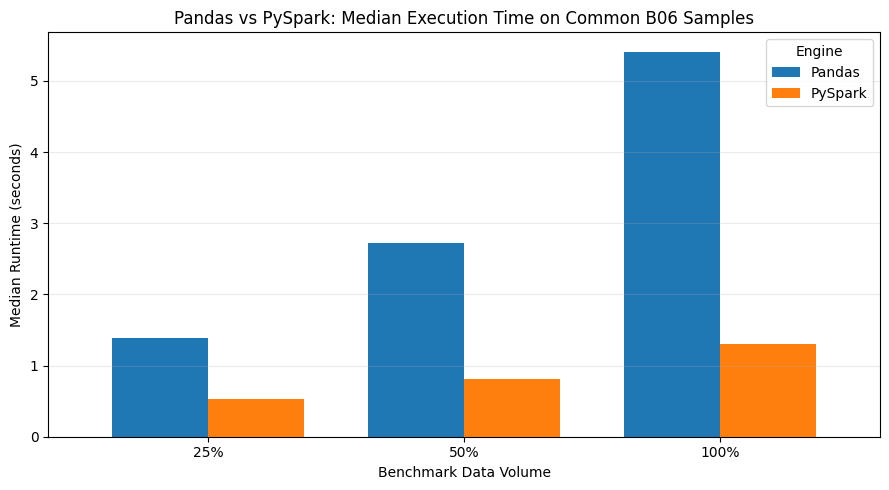

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_runtime.png | 91464 bytes | 300 dpi | 9 x 5 inches


In [64]:
# [CHANGE] Step 8.2 — Plot median execution time on the common B06 dataset

plot_data = runtime_pivot.set_index("sample")[["pandas", "spark"]]
fig, ax = plt.subplots(figsize=(9, 5))
plot_data.plot(kind="bar", ax=ax, width=0.75)
ax.set_title("Pandas vs PySpark: Median Execution Time on Common B06 Samples")
ax.set_xlabel("Benchmark Data Volume")
ax.set_ylabel("Median Runtime (seconds)")
ax.legend(["Pandas", "PySpark"], title="Engine")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()

runtime_plot_path = OUTPUT_DIR / "B16_compare_runtime.png"
fig.savefig(runtime_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(
    f"Saved: {runtime_plot_path} | {runtime_plot_path.stat().st_size} bytes | "
    f"300 dpi | 9 x 5 inches"
)

### 8.3 Plot relative PySpark speedup

**Input:** `pyspark_speedup_over_pandas` from `runtime_pivot`. **Process:** Plot the runtime ratio across sample sizes and include a reference line at 1, representing equal median runtime. A value above 1 indicates PySpark is faster; below 1 indicates Pandas is faster. **Output:** `B16_compare_speedup.png` at 300 dpi.

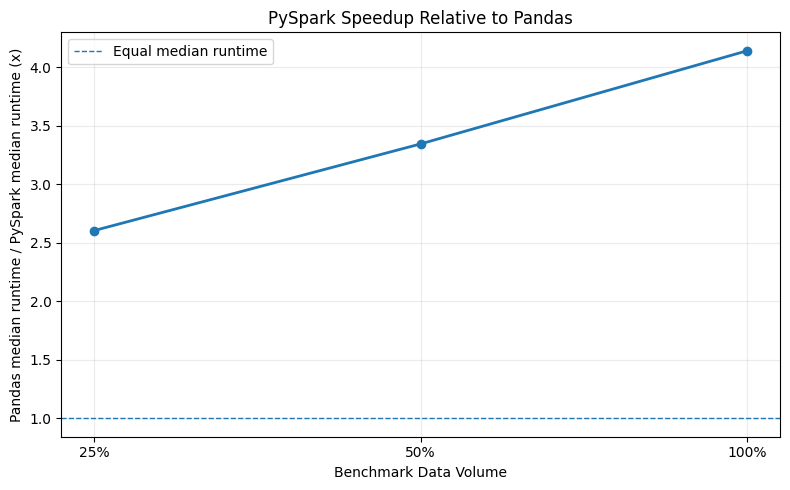

Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_speedup.png | 118337 bytes | 300 dpi | 8 x 5 inches


In [65]:
# [CHANGE] Step 8.3 — Plot PySpark speedup relative to Pandas

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    runtime_pivot["sample"].astype(str),
    runtime_pivot["pyspark_speedup_over_pandas"],
    marker="o",
    linewidth=2,
)
ax.axhline(y=1, linestyle="--", linewidth=1, label="Equal median runtime")
ax.set_title("PySpark Speedup Relative to Pandas")
ax.set_xlabel("Benchmark Data Volume")
ax.set_ylabel("Pandas median runtime / PySpark median runtime (x)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

speedup_plot_path = OUTPUT_DIR / "B16_compare_speedup.png"
fig.savefig(speedup_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(
    f"Saved: {speedup_plot_path} | {speedup_plot_path.stat().st_size} bytes | "
    f"300 dpi | 8 x 5 inches"
)


## 9. Interpretation, limitations, and final outputs

Interpret the measured results by answering:

1. Which engine is faster at each tested data volume?
2. How does runtime increase as the input grows from 25% to 100%?
3. Does the relative performance gap widen or narrow?
4. Does PySpark provide a measurable advantage for this grouped aggregation on the available machine?

The interpretation must refer to the generated summary table and figures. Do not claim that one engine is universally faster.

### Experimental limitations

- **Single-machine execution:** PySpark runs in local mode, so the experiment does not measure a multi-node Spark cluster.
- **Workload specificity:** The benchmark tests one grouped aggregation workload, not every possible big-data operation.
- **Runtime environment:** CPU availability, memory pressure, filesystem caching, and background processes may affect the measurements.
- **Repeated local reads:** Operating-system filesystem caching is not cleared between repetitions. Results therefore represent repeated local execution, not cold-storage performance.
- **Sample generation:** One shared set of benchmark subsets is created from canonical B06 before timing; both engines read the same physical CSV paths, generated from the independently validated Parquet samples. Parquet-to-CSV conversion and sample generation are not part of the measured workload. Results concern CSV I/O plus aggregation, not Parquet performance.

### Final output inventory

| Output | Description |
|---|---|
| `B16_compare_environment.csv` | Hardware and software environment |
| `B16_compare_schema_check.csv` | B06/B07 column and schema comparison |
| `B16_compare_input_profile.csv` | Independent B06 and B07 input/S0 profiles |
| `B16_compare_population_checks.csv` | Full-input and S0 population agreement checks |
| `B16_compare_group_checks.csv` | Race-by-loan-type population comparison |
| `B16_compare_group_value_checks.csv` | Shared categorical grouping-value frequencies |
| `B16_compare_correctness_summary.csv` | Cross-engine correctness summary |
| `B16_compare_correctness_detail_*.csv` | Eligible grouped comparison details; lender identifiers are excluded |
| `B16_compare_raw_racial_gap.csv` | Racial denial rates and gaps versus White |
| `B16_compare_sample_manifest.csv` | Actual sample sizes, columns, paths, and storage sizes |
| `B16_compare_csv_conversion_check.csv` | Full CSV-to-Parquet sample equivalence checks |
| `B16_compare_spark_sample_read_check.csv` | Spark CSV reader preflight |
| `B16_compare_benchmark_source_check.csv` | Validation of the canonical B06 S0 benchmark projection |
| `B16_compare_benchmark_correctness.csv` | Benchmark equivalence checks at each volume |
| `B16_compare_benchmark_correctness_*.csv` | Per-sample benchmark discrepancy details when present |
| `B16_compare_benchmark_runs.csv` | Individual execution measurements |
| `B16_compare_benchmark_summary.csv` | Median runtime, speedup, and runtime growth |
| `B16_compare_benchmark_summary_by_engine.csv` | Per-engine runtime statistics |
| `B16_compare_runtime.png` | Runtime comparison chart |
| `B16_compare_speedup.png` | Relative speedup chart |
| `B16_compare_execution_log.csv` | Final expected-artifact existence check |

The notebook provides empirical evidence for Sections 7 and 8 of the technical report. All reported numerical findings must be taken from generated outputs after a successful run.


## 10. Final execution checks

The final cell confirms that the expected benchmark artifacts exist and records the notebook's completion status.

The notebook should be restarted and executed from top to bottom before the generated outputs are used in the report.

### 10.1A Define the expected output inventory

**Input:** The output files produced by Sections 0–8.  
**Process:** List the required validation, correctness, benchmark, summary, and visualization artifacts expected after a complete run.  
**Output:** `EXPECTED_OUTPUTS` for the final execution check.


In [66]:
# [CHANGE] Step 10.1A — Define required B16 output artifacts
EXPECTED_OUTPUTS = [
    "B16_compare_environment.csv",
    "B16_compare_schema_check.csv",
    "B16_compare_input_profile.csv",
    "B16_compare_population_checks.csv",
    "B16_compare_group_checks.csv",
    "B16_compare_group_value_checks.csv",
    "B16_compare_correctness_summary.csv",
    "B16_compare_raw_racial_gap.csv",
    "B16_compare_sample_manifest.csv",
    "B16_compare_csv_conversion_check.csv",
    "B16_compare_spark_sample_read_check.csv",
    "B16_compare_benchmark_source_check.csv",
    "B16_compare_benchmark_correctness.csv",
    "B16_compare_benchmark_runs.csv",
    "B16_compare_benchmark_summary.csv",
    "B16_compare_benchmark_summary_by_engine.csv",
    "B16_compare_runtime.png",
    "B16_compare_speedup.png",
]

### 10.1B Inspect the generated artifact inventory

**Input:** `EXPECTED_OUTPUTS` and the B16 output directory.  
**Process:** Check whether each expected artifact exists and record its byte size. Missing outputs remain visible in the report rather than being silently ignored.  
**Output:** `artifact_status`, a table of expected artifact presence and file sizes.


In [67]:
# [ADD] Step 10.1B — Build the final artifact status table
def build_artifact_status(expected_names, output_dir):
    """Return existence and file-size metadata for each expected artifact."""
    rows = []
    for name in expected_names:
        path = Path(output_dir) / name
        rows.append({
            "artifact": name,
            "exists": path.is_file(),
            "size_bytes": path.stat().st_size if path.is_file() else 0,
        })
    return pd.DataFrame(rows)


artifact_status = build_artifact_status(EXPECTED_OUTPUTS, OUTPUT_DIR)
display(artifact_status)


,artifact,exists,size_bytes
0,B16_compare_environment.csv,True,674
1,B16_compare_schema_check.csv,True,7621
2,B16_compare_input_profile.csv,True,481
3,B16_compare_population_checks.csv,True,305
4,B16_compare_group_checks.csv,True,1743
5,B16_compare_group_value_checks.csv,True,3218
6,B16_compare_correctness_summary.csv,True,604
7,B16_compare_raw_racial_gap.csv,True,1155
8,B16_compare_sample_manifest.csv,True,1690
9,B16_compare_csv_conversion_check.csv,True,651


### 10.1C Export the execution log and validate notebook completion

**Input:** The artifact-status table.  
**Process:** Save the execution log, print its path/size/dimensions, and raise an error if any required artifact is missing.  
**Output:** `B16_compare_execution_log.csv` and an explicit completion verdict.


In [68]:
# [CHANGE] Step 10.1C — Save final execution status and validate outputs
execution_log_path = OUTPUT_DIR / "B16_compare_execution_log.csv"
artifact_status.to_csv(execution_log_path, index=False)
report_output_metadata(
    execution_log_path, len(artifact_status), len(artifact_status.columns)
)

missing_artifacts = artifact_status.loc[~artifact_status["exists"], "artifact"].tolist()
if missing_artifacts:
    raise FileNotFoundError(
        "Required B16 outputs are missing: " + ", ".join(missing_artifacts)
    )
print("[PASS] All expected comparison and benchmark artifacts exist.")
print("B16 output directory:", OUTPUT_DIR.resolve())


Saved: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output\B16_compare_execution_log.csv | size_bytes=813 | rows=18 | columns=3
[PASS] All expected comparison and benchmark artifacts exist.
B16 output directory: D:\whoever holds this long stick\neu_ba65_bigdata_hmda_2024\B16 - Pandas Spark Compare\output
